# HT-9046MX — Data Analysis to ML, Presentation Edition

Notebook สำหรับ Google Colab ที่เล่าเรื่องตั้งแต่ข้อมูลดิบไปจนถึงการเทรน ML แบบเป็น Phase
โดยยึด `README_System.md` และกติกาหน้างานล่าสุดเป็นหลัก

**คำถามหลัก**

- ข้อมูลของแต่ละเครื่องเพียงพอและเทียบกันได้หรือไม่
- Baseline รายเครื่อง–ราย module–ราย SV แตกต่างกันอย่างไร
- `Hp_2nd` อยู่นอกช่วงอ้างอิง 180–230 psi ที่ไหนและต่อเนื่องหรือไม่
- pressure, valve และ temperature เปลี่ยนสัมพันธ์กันอย่างไร
- จะสร้าง feature และ validation สำหรับ ML โดยไม่ทำให้ข้อมูลอนาคตรั่วเข้าอดีตได้อย่างไร

**กติกา `Hp_2nd` ที่ใช้ในฉบับนี้**

- `Hp_2nd < 180 psi` เป็นเพียงหลักฐานคัดกรอง undercharge; `Hp_2nd >= 180 psi` ไม่เพิ่ม undercharge score
- `Hp_2nd > 230 psi` เป็น high-side investigation แยกต่างหาก ไม่ยืนยันสาเหตุจากระบบน้ำ
- General anomaly และ undercharge/leak screening เป็นคนละผลลัพธ์ ห้ามใช้แทนกัน

## แผนงานทั้ง Notebook

| Phase | คำถาม | ผลลัพธ์หลัก | Visual ที่เลือก |
|---:|---|---|---|
| 0 | วิเคราะห์ภายใต้กติกาอะไร | Data contract และข้อจำกัด | Process map |
| 1 | ข้อมูลครอบคลุมแค่ไหน | เครื่องสำหรับ development และ external test | Horizontal bar |
| 2 | ข้อมูลส่วนไหนเทียบกันได้ | สัดส่วน operating state และ baseline eligibility | 100% stacked bar |
| 3 | Baseline เท่ากันหรือไม่ | Calibration ราย machine × module × SV | Heatmap + interval dot plot |
| 4 | ตัวแปรสัมพันธ์กันอย่างไร | Correlation และ drill-down ราย profile | Heatmap + scatter + timeline |
| 5 | ค่าเปลี่ยนตามเวลาหรือมีจุดกระโดดหรือไม่ | Drift และ service/refill candidates | Line + ranked bar |
| 6 | แปลงข้อมูลเป็น feature อย่างไร | 1-second event response + response-preserving minute features | Event curves + before/after distribution |
| 7 | เทรน ML อย่างไร | Minute-only เทียบ Hybrid 30/120 วินาที | Score, sensitivity + server cost |
| 8 | โมเดลถ่ายโอนข้ามเวลา/เครื่องได้หรือไม่ | Temporal, LOMO และ external test | Small-multiple bars |
| 9 | พร้อมใช้งานจริงหรือยัง | ข้อสรุป, caveat และ deployment plan | Decision checklist |

```text
Raw logs → Data quality → State qualification → Calibration profiles
         → Relationships & drift → Relative features → ML training
         → Temporal / LOMO / External test → Shadow mode + technician feedback
```

## วิธีเล่า Notebook นี้ในห้องประชุม

1. เริ่มจาก **ข้อมูลครอบคลุมพอหรือไม่** และแยกเครื่อง development ออกจากเครื่อง external test
2. อธิบายว่า **ข้อมูลไม่ใช่ทุกแถวที่เทียบกันได้** จึงต้อง qualification และแยก SV ON/OFF
3. แสดงว่า **Baseline ต่างกันจริง** จึงต้อง calibrate ราย machine × module × SV
4. โฟกัส `Hp_2nd` ด้วยช่วงอ้างอิง 180–230 psi: ต่ำกว่า 180 เป็น undercharge screening และสูงกว่า 230 เป็น high-side investigation
5. ต่อด้วย **relationship, drift และ service/refill candidates** เพื่ออธิบายว่าค่าต่าง ๆ เปลี่ยนร่วมกันอย่างไร
6. แปลงเป็น relative features แล้วเทรน **general anomaly model** โดยไม่เรียกว่า leak classifier
7. ปิดท้ายด้วย temporal, LOMO, external test และข้อจำกัดที่ต้องเก็บเพิ่มก่อนใช้งานจริง

> เส้นเรื่องสำคัญ: “ค่าต่างจากเครื่องอื่น” ไม่เท่ากับ “เครื่องเสีย” และ “anomaly” ไม่เท่ากับ “leak”

# Phase 0 — Data contract, setup and reproducibility

บน Colab ให้วางทั้งโฟลเดอร์โปรเจกต์ `OPERATION_P` ไว้ใน Google Drive แล้วตั้ง `PROJECT_ROOT_OVERRIDE` หากระบบหาโฟลเดอร์ไม่พบ สามารถเปิด `MOUNT_GOOGLE_DRIVE = True` เพื่อ mount Drive จาก notebook ได้

In [1]:
import importlib.util
import json
import sys
import subprocess
from pathlib import Path

required = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "polars": "polars",
    "pyarrow": "pyarrow",
    "ipywidgets": "ipywidgets",
    "sklearn": "scikit-learn",
}
missing = [pip_name for module, pip_name in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, Markdown, display
import matplotlib.dates as mdates
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
import joblib

try:
    import ipywidgets as widgets
except Exception:
    widgets = None

MOUNT_GOOGLE_DRIVE = False
PROJECT_ROOT_OVERRIDE = ""  # ตัวอย่าง: /content/drive/MyDrive/OPERATION_P

if "google.colab" in sys.modules and MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

def find_project_root():
    candidates = []
    if PROJECT_ROOT_OVERRIDE:
        candidates.append(Path(PROJECT_ROOT_OVERRIDE))
    candidates += [
        Path.cwd(),
        Path.cwd().parent,
        Path("/content/OPERATION_P"),
        Path("/content/drive/MyDrive/OPERATION_P"),
    ]
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if (candidate / "README_System.md").exists():
            return candidate
    raise FileNotFoundError(
        "ไม่พบ README_System.md — กรุณาตั้ง PROJECT_ROOT_OVERRIDE ให้ชี้ไปยังโฟลเดอร์ OPERATION_P"
    )

PROJECT_ROOT = find_project_root()
BASE_OUT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_colab_analysis"
ML_OUT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_ml_calibration"
PRESENTATION_OUT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_presentation_v2"
FIG_OUT = PRESENTATION_OUT / "figures"
FIG_OUT.mkdir(parents=True, exist_ok=True)

required_artifacts = [
    BASE_OUT / "analysis_summary.json",
    BASE_OUT / "baseline_stats.csv",
    BASE_OUT / "spearman_correlations.csv",
    BASE_OUT / "cache" / "minute_module_state.parquet",
    ML_OUT / "ml_validation_summary.json",
    ML_OUT / "temporal_validation.csv",
    ML_OUT / "lomo_validation.csv",
    ML_OUT / "external_test_results.csv",
]
missing_artifacts = [str(p) for p in required_artifacts if not p.exists()]
if missing_artifacts:
    raise FileNotFoundError(
        "ผลวิเคราะห์ที่ต้องใช้ยังไม่ครบ กรุณารัน HT9046MX_State_Aware_Baseline_Analysis.ipynb "
        "และ HT9046MX_ML_Calibration_LOMO.ipynb ก่อน\n" + "\n".join(missing_artifacts)
    )

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 160,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#243447",
    "text.color": "#243447",
    "font.size": 10,
})

PALETTE = {
    "blue": "#2F6BFF",
    "gold": "#D79A24",
    "orange": "#E97932",
    "olive": "#7D8E45",
    "pink": "#C85D8E",
    "ink": "#243447",
    "light": "#DCE6F2",
    "grey": "#8796A5",
}

def savefig(name):
    path = FIG_OUT / name
    plt.savefig(path, bbox_inches="tight", facecolor="white")
    return path

print(f"Project root: {PROJECT_ROOT}")
print(f"Figures: {FIG_OUT}")

Project root: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P
Figures: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_presentation_v2\figures


# Phase 1 — Load data and pass the quality gate

In [2]:
with open(BASE_OUT / "analysis_summary.json", encoding="utf-8") as f:
    analysis_summary = json.load(f)
with open(ML_OUT / "ml_validation_summary.json", encoding="utf-8") as f:
    ml_summary = json.load(f)

def read_csv(name, root=BASE_OUT):
    return pd.read_csv(root / name, dtype={"machine_number": "string"})

inventory = read_csv("machine_inventory.csv")
state_counts = read_csv("state_counts.csv")
coverage = read_csv("module_coverage.csv")
readiness = read_csv("machine_ml_readiness.csv")
baseline = read_csv("baseline_stats.csv")
comparability = read_csv("baseline_comparability.csv")
correlations = read_csv("spearman_correlations.csv")
lag_relationships = read_csv("lag_relationships.csv")
best_lags = read_csv("best_lag_relationships.csv")
daily = read_csv("daily_baseline_trends.csv")

split_manifest = read_csv("machine_split_manifest.csv", ML_OUT)
temporal = read_csv("temporal_validation.csv", ML_OUT)
lomo = pd.read_csv(ML_OUT / "lomo_validation.csv", dtype={"held_out_machine": "string"})
external = read_csv("external_test_results.csv", ML_OUT)
portability = pd.read_csv(ML_OUT / "feature_portability.csv")

for frame in [inventory, state_counts, coverage, readiness, baseline, correlations, lag_relationships,
              best_lags, daily, split_manifest, temporal, external]:
    if "machine_number" in frame.columns:
        frame["machine_number"] = frame["machine_number"].astype("string").str.zfill(3)
lomo["held_out_machine"] = lomo["held_out_machine"].astype("string").str.zfill(3)
daily["date"] = pd.to_datetime(daily["date"])

minute = pl.read_parquet(BASE_OUT / "cache" / "minute_module_state.parquet").with_columns(
    pl.col("machine_number").cast(pl.Utf8).str.zfill(3),
    pl.col("minute").cast(pl.Datetime),
).sort(["machine_number", "module", "minute"])

control_states = ["ChangeValve", "MValveHome", "AdjustValve"]
minute = minute.with_columns(
    pl.when(pl.col("global_status") == "Stop")
    .then(pl.lit("GLOBAL_STOP"))
    .when(
        pl.col("module_status").is_in(control_states)
        | (pl.col("busy") == 1)
        | (pl.col("valve") < 0)
    )
    .then(pl.lit("CONTROL_SEQUENCE"))
    .when(pl.col("module_status") == "Off")
    .then(pl.lit("RUN_MODULE_OFF"))
    .when(
        (pl.col("global_status") == "Run")
        & (pl.col("module_status") == "On")
        & (pl.col("busy") == 0)
        & (pl.col("valve") >= 0)
        & (pl.col("sv") == "Off")
    )
    .then(pl.lit("RUN_ON_SV_OFF"))
    .when(
        (pl.col("global_status") == "Run")
        & (pl.col("module_status") == "On")
        & (pl.col("busy") == 0)
        & (pl.col("valve") >= 0)
        & (pl.col("sv") == "On")
    )
    .then(pl.lit("RUN_ON_SV_ON"))
    .otherwise(pl.lit("UNCLASSIFIED"))
    .alias("state")
)
minute = minute.with_columns(
    (
        (pl.col("state") != pl.col("state").shift(1).over(["machine_number", "module"]))
        | (pl.col("minute").diff().over(["machine_number", "module"]).dt.total_minutes() > 2)
    ).fill_null(True).alias("segment_start")
).with_columns(
    pl.col("segment_start").cast(pl.Int64).cum_sum().over(["machine_number", "module"]).alias("segment_id")
).with_columns(
    pl.col("minute").cum_count().over(["machine_number", "module", "segment_id"]).alias("minutes_in_state")
).with_columns(
    (
        pl.col("state").is_in(["RUN_ON_SV_OFF", "RUN_ON_SV_ON"])
        & (pl.col("minutes_in_state") >= 3)
    ).alias("baseline_eligible")
)

machines = sorted(inventory["machine_number"].astype(str).unique())
development_machines = ml_summary["development_machines"]
external_machines = ml_summary["external_test_machines"]
module_names = {
    1: "Index L Arm1", 2: "Index R Arm1", 3: "Index L Arm2", 4: "Index R Arm2",
    5: "SH1", 6: "SH2", 7: "Hot1", 8: "Hot2",
}

print(f"Loaded {len(machines)} machines and {minute.height:,} minute-module rows")

Loaded 19 machines and 3,548,928 minute-module rows


## 1.1 Executive overview

กระบวนการที่ใช้จริง:

`26.16M raw rows` → `state qualification` → `3.55M minute-module rows` → `baseline by machine × module × SV` → `relative features` → `temporal + LOMO + external validation`

In [3]:
cards = [
    ("Parquet files", f"{analysis_summary['parquet_files']:,}"),
    ("Raw rows", f"{analysis_summary['raw_rows'] / 1e6:.2f}M"),
    ("Machines", f"{analysis_summary['machines']}"),
    ("Minute-module rows", f"{analysis_summary['minute_module_rows'] / 1e6:.2f}M"),
    ("Baseline eligible", f"{analysis_summary['baseline_eligible_rows'] / analysis_summary['minute_module_rows']:.1%}"),
    ("Calibration-ready machines", f"{ml_summary['development_machine_count']} / {analysis_summary['machines']}"),
]
html = "<div style='display:grid;grid-template-columns:repeat(3,minmax(180px,1fr));gap:12px'>"
for label, value in cards:
    html += (
        "<div style='padding:16px;border:1px solid #dce6f2;border-radius:12px;background:#fff'>"
        f"<div style='font-size:13px;color:#68788a'>{label}</div>"
        f"<div style='font-size:28px;font-weight:700;color:#243447'>{value}</div></div>"
    )
html += "</div>"
display(HTML(html))

display(Markdown(
    f"**ช่วงข้อมูล:** {analysis_summary['date_start'][:10]} ถึง {analysis_summary['date_end'][:10]}  "
    f"  \n**Development:** {', '.join(development_machines)}  "
    f"  \n**External test / shadow mode:** {', '.join(external_machines)}"
))

**ช่วงข้อมูล:** 2026-08-04 ถึง 2026-09-01    
**Development:** 017, 022, 024, 029, 041, 057, 058, 070, 072, 081, 082, 083    
**External test / shadow mode:** 056, 063, 071, 115, 118, 119, 124

## 1.2 Data coverage — เครื่องไหนมีข้อมูลพอสำหรับ calibration

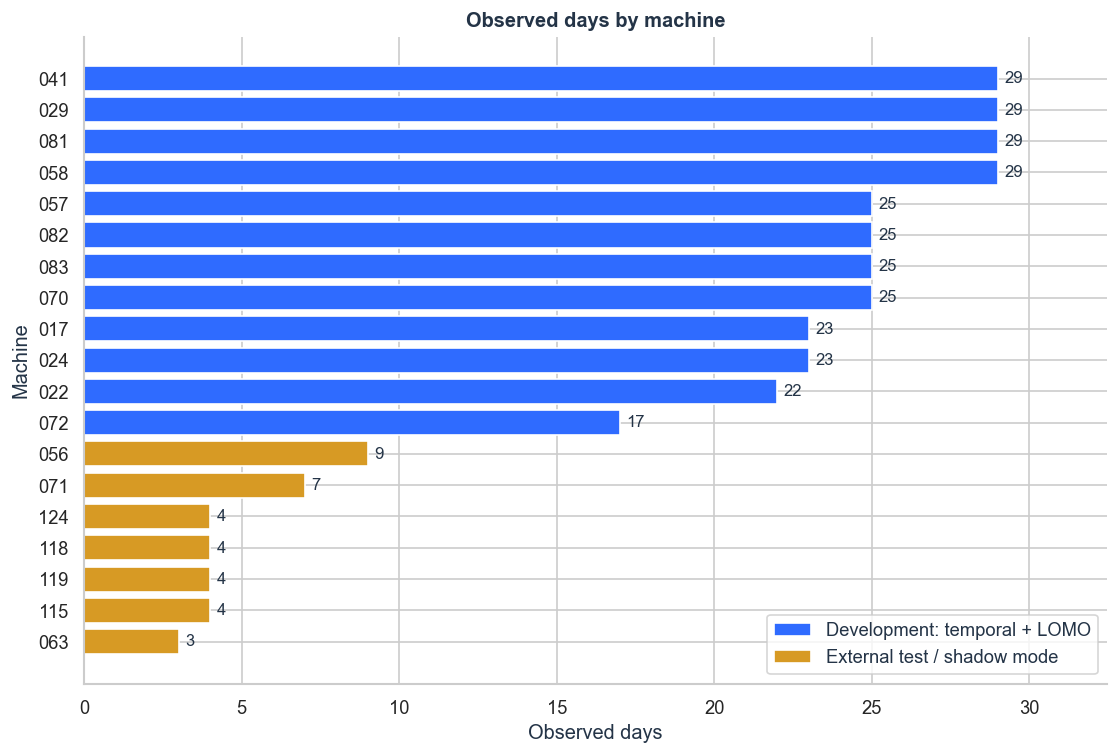

In [4]:
plot_inventory = inventory.merge(split_manifest, on="machine_number", how="left")
plot_inventory["role"] = plot_inventory["role"].fillna("external_test")
plot_inventory = plot_inventory.sort_values("observed_days", ascending=True)
colors = plot_inventory["role"].map({
    "development_temporal_lomo": PALETTE["blue"],
    "external_test": PALETTE["gold"],
}).fillna(PALETTE["gold"])

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_inventory["machine_number"], plot_inventory["observed_days"], color=colors)
ax.set_title("Observed days by machine")
ax.set_xlabel("Observed days")
ax.set_ylabel("Machine")
ax.set_xlim(0, max(plot_inventory["observed_days"]) * 1.12)
ax.bar_label(bars, padding=4, fmt="%.0f")
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor=PALETTE["blue"], label="Development: temporal + LOMO"),
    Patch(facecolor=PALETTE["gold"], label="External test / shadow mode"),
], loc="lower right")
sns.despine()
savefig("01_machine_coverage.png")
plt.show()

**วิธีอ่าน:** สีน้ำเงินคือ 12 เครื่องที่มีอย่างน้อย 6 modules พร้อมสร้าง calibration profile ส่วนสีทองคือ 7 เครื่องที่มีข้อมูลน้อยหรือวันไม่พอ จึงกันไว้เป็น external test โดยไม่ใช้สร้าง profile หรือ train model

# Phase 2 — Operating-state qualification

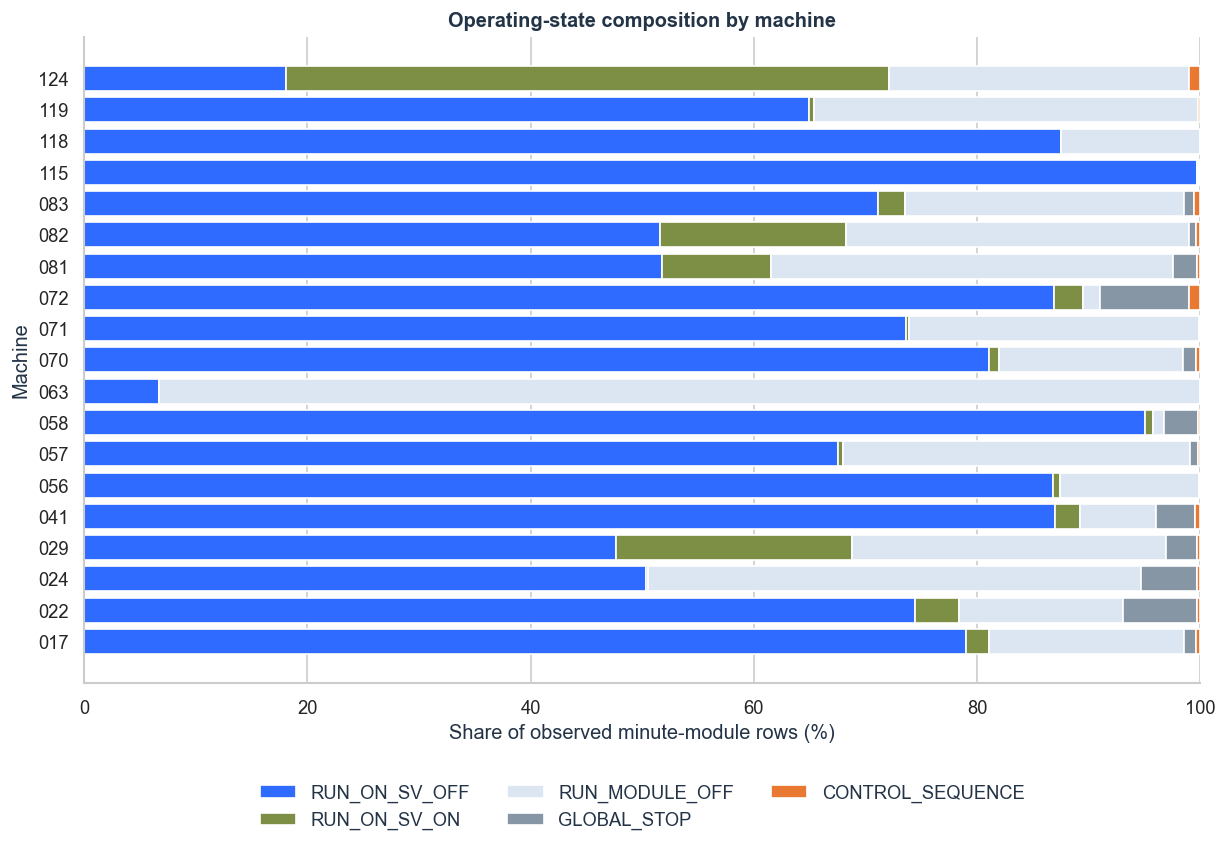

In [5]:
state_order = ["RUN_ON_SV_OFF", "RUN_ON_SV_ON", "RUN_MODULE_OFF", "GLOBAL_STOP", "CONTROL_SEQUENCE", "UNCLASSIFIED"]
state_palette = {
    "RUN_ON_SV_OFF": PALETTE["blue"],
    "RUN_ON_SV_ON": PALETTE["olive"],
    "RUN_MODULE_OFF": PALETTE["light"],
    "GLOBAL_STOP": PALETTE["grey"],
    "CONTROL_SEQUENCE": PALETTE["orange"],
    "UNCLASSIFIED": PALETTE["pink"],
}
machine_state = state_counts.groupby(["machine_number", "state"], as_index=False)["minutes"].sum()
machine_state["share"] = machine_state["minutes"] / machine_state.groupby("machine_number")["minutes"].transform("sum")
state_wide = machine_state.pivot(index="machine_number", columns="state", values="share").fillna(0)
state_wide = state_wide.reindex(columns=[s for s in state_order if s in state_wide.columns], fill_value=0)

fig, ax = plt.subplots(figsize=(12, 7))
left = np.zeros(len(state_wide))
y = np.arange(len(state_wide))
for state in state_wide.columns:
    values = state_wide[state].to_numpy() * 100
    ax.barh(y, values, left=left, label=state, color=state_palette[state])
    left += values
ax.set_yticks(y, state_wide.index)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of observed minute-module rows (%)")
ax.set_ylabel("Machine")
ax.set_title("Operating-state composition by machine")
ax.legend(ncol=3, bbox_to_anchor=(0.5, -0.13), loc="upper center", frameon=False)
sns.despine()
savefig("02_state_composition.png")
plt.show()

Baseline ใช้เฉพาะ run state ที่เทียบเคียงได้และแยก SV ออกจากกัน ส่วน `GLOBAL_STOP`, `CONTROL_SEQUENCE`, `MValveHome`, negative valve และช่วง transient ไม่ถูกนำไปปนกับ normal cooling baseline

# Phase 3 — Baseline calibration

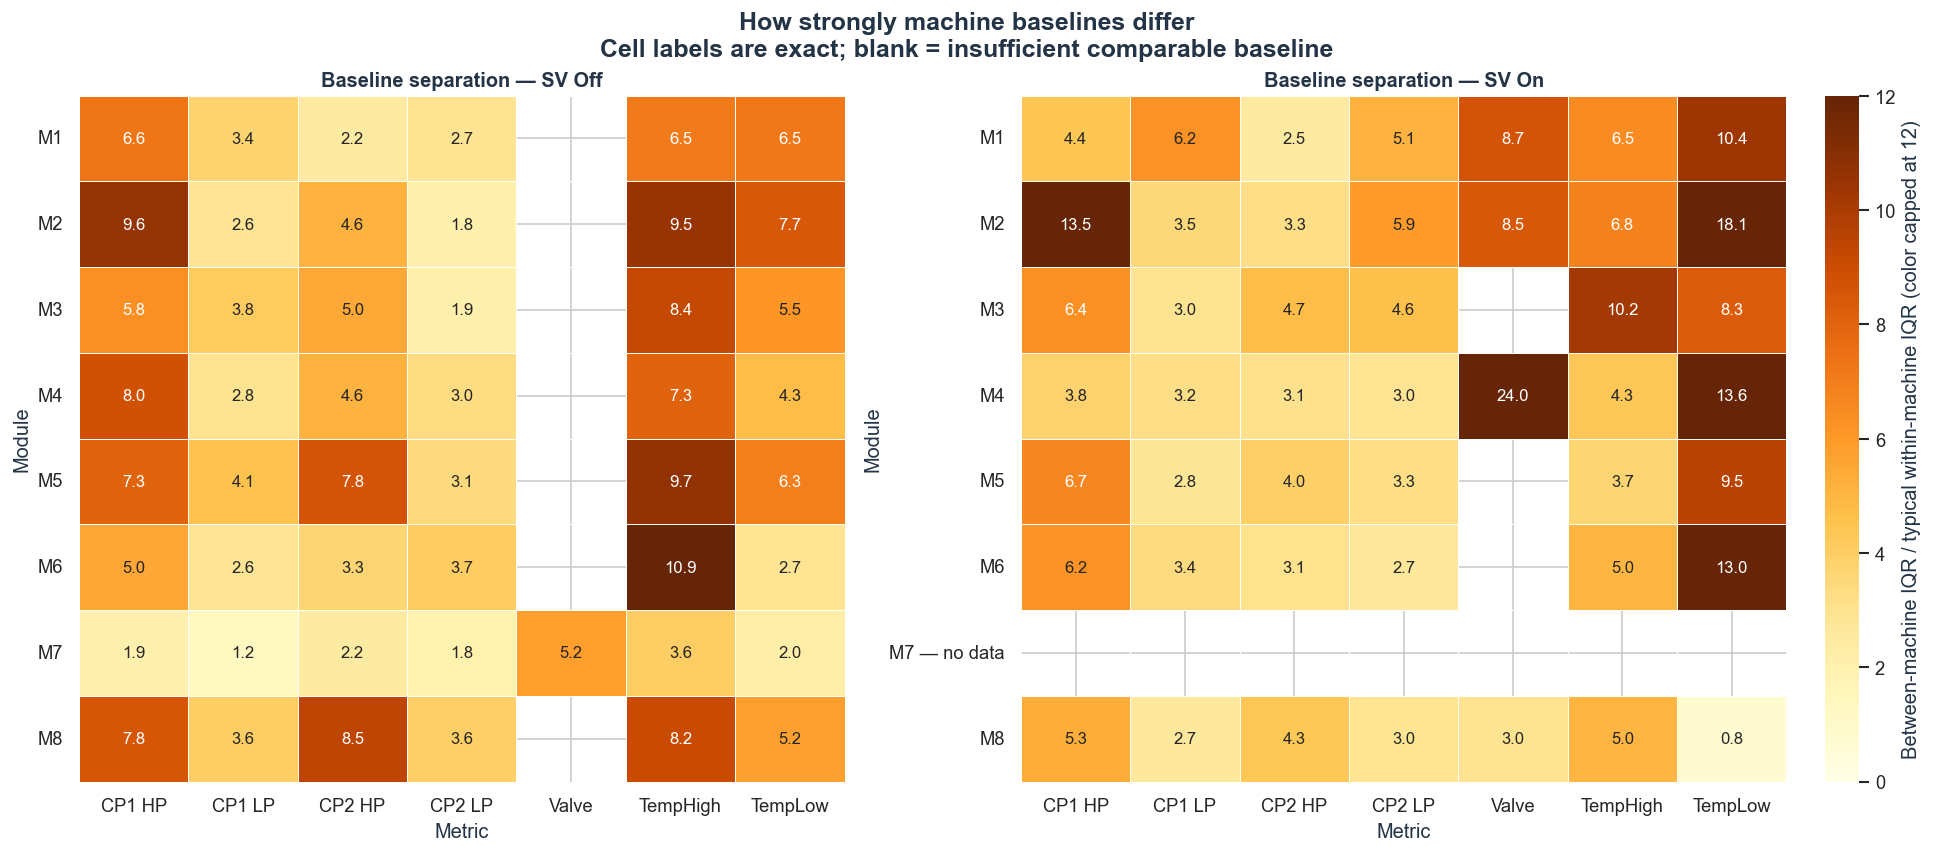

**คำตอบ:** baseline ไม่เท่ากัน — ค่ากลางของอัตราส่วนความต่างระหว่างเครื่องต่อความผันผวนภายในเครื่อง = **4.64 เท่า** และสูงสุด **24.0 เท่า** จึงควร calibrate แยก machine × module × SV  
สีถูก cap ที่ 12 เพื่อให้ค่ากลางอ่านง่าย แต่ตัวเลขในช่องเป็นค่าจริง และช่องว่างหมายถึงข้อมูลเทียบเคียงไม่พอ

In [6]:
metric_labels = {
    "hp1": "CP1 HP", "lp1": "CP1 LP", "hp2": "CP2 HP", "lp2": "CP2 LP",
    "valve": "Valve", "temphi": "TempHigh", "templo": "TempLow",
}
fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
for ax, sv in zip(axes, ["Off", "On"]):
    part = comparability[comparability["sv"] == sv].copy()
    heat = part.pivot(index="module", columns="metric", values="between_to_within_ratio")
    ordered_metrics = [m for m in metric_labels if m in heat.columns]
    heat = heat.reindex(index=range(1, 9), columns=ordered_metrics)
    heat.columns = [metric_labels[m] for m in heat.columns]
    color_cap = min(12, np.nanmax(heat.values))
    sns.heatmap(
        heat, ax=ax, cmap="YlOrBr", vmin=0, vmax=color_cap,
        annot=True, fmt=".1f", linewidths=.5, cbar=ax is axes[-1],
        cbar_kws={"label": "Between-machine IQR / typical within-machine IQR (color capped at 12)"},
    )
    row_labels = [f"M{i}" + (" — no data" if heat.loc[i].isna().all() else "") for i in heat.index]
    ax.set_yticklabels(row_labels, rotation=0)
    ax.set_title(f"Baseline separation — SV {sv}")
    ax.set_xlabel("Metric")
    ax.set_ylabel("Module")
fig.suptitle("How strongly machine baselines differ\nCell labels are exact; blank = insufficient comparable baseline", fontsize=15, fontweight="bold")
savefig("03_baseline_comparability.png")
plt.show()

median_ratio = comparability["between_to_within_ratio"].median()
high_ratio = comparability["between_to_within_ratio"].max()
display(Markdown(
    f"**คำตอบ:** baseline ไม่เท่ากัน — ค่ากลางของอัตราส่วนความต่างระหว่างเครื่องต่อความผันผวนภายในเครื่อง = "
    f"**{median_ratio:.2f} เท่า** และสูงสุด **{high_ratio:.1f} เท่า** จึงควร calibrate แยก machine × module × SV  \n"
    "สีถูก cap ที่ 12 เพื่อให้ค่ากลางอ่านง่าย แต่ตัวเลขในช่องเป็นค่าจริง และช่องว่างหมายถึงข้อมูลเทียบเคียงไม่พอ"
))

## 3.1 Baseline map — ทุกเครื่องและทุก module

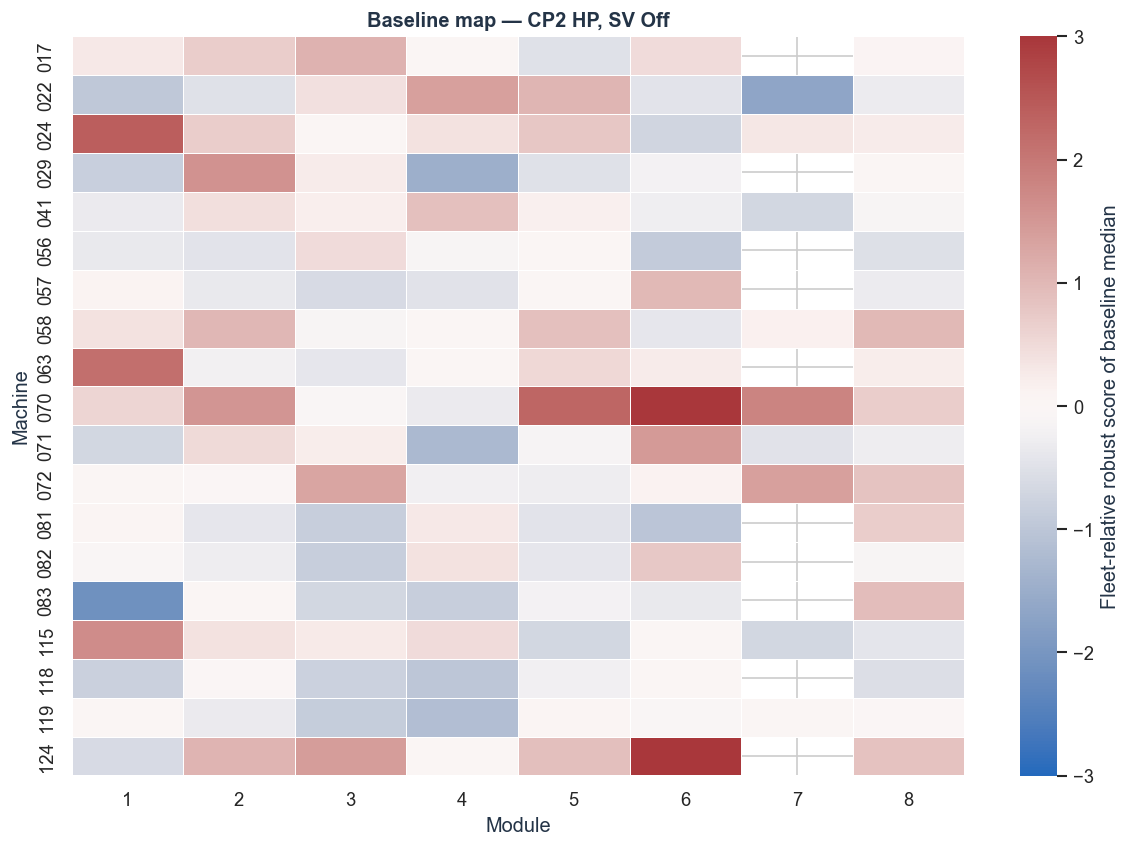

### Interactive baseline map

interactive(children=(Dropdown(description='Metric', index=2, options=('hp1', 'lp1', 'hp2', 'lp2', 'valve', 't…

In [7]:
def robust_center_scale(series):
    median = series.median()
    iqr = series.quantile(.75) - series.quantile(.25)
    scale = iqr if np.isfinite(iqr) and iqr > 1e-9 else 1.0
    return (series - median) / scale

def plot_baseline_map(metric="hp2", sv="Off", save=False):
    value_col = f"{metric}_median"
    part = baseline[(baseline["sv"] == sv) & baseline[value_col].notna()].copy()
    part["fleet_relative"] = part.groupby("module")[value_col].transform(robust_center_scale)
    heat = part.pivot(index="machine_number", columns="module", values="fleet_relative")
    heat = heat.reindex(index=machines, columns=range(1, 9))
    fig, ax = plt.subplots(figsize=(12, 8))
    sns.heatmap(
        heat, cmap="vlag", center=0, vmin=-3, vmax=3, linewidths=.35,
        cbar_kws={"label": "Fleet-relative robust score of baseline median"}, ax=ax,
    )
    ax.set_title(f"Baseline map — {metric_labels[metric]}, SV {sv}")
    ax.set_xlabel("Module")
    ax.set_ylabel("Machine")
    if save:
        savefig(f"04_baseline_map_{metric}_{sv.lower()}.png")
    plt.show()

plot_baseline_map("hp2", "Off", save=True)

if widgets is not None:
    display(Markdown("### Interactive baseline map"))
    widgets.interact(
        plot_baseline_map,
        metric=widgets.Dropdown(options=list(metric_labels), value="hp2", description="Metric"),
        sv=widgets.Dropdown(options=["Off", "On"], value="Off", description="SV"),
        save=widgets.fixed(False),
    )

สีใน heatmap เป็นตำแหน่งของ baseline เทียบกับเครื่องอื่น **ภายใน module และ SV เดียวกัน** ไม่ใช่ health score
สีเข้มจึงหมายถึง “ต่างจาก fleet” ไม่ได้หมายถึงเสีย และช่องว่างหมายถึง baseline ที่เทียบเคียงได้มีไม่พอ.

## 3.2 Baseline interval — ค่าจริงรายเครื่อง

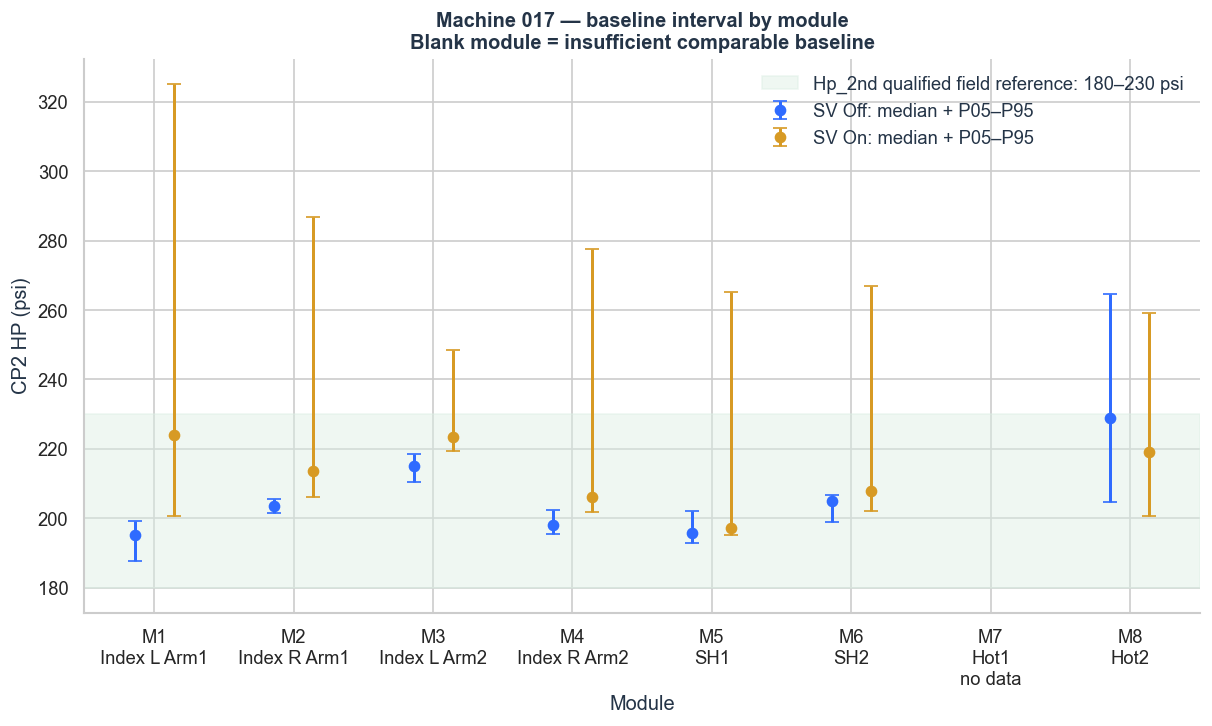

### Interactive machine baseline interval

interactive(children=(Dropdown(description='Machine', options=('017', '022', '024', '029', '041', '056', '057'…

In [8]:
def plot_machine_baseline(machine="017", metric="hp2", save=False):
    p = baseline[(baseline["machine_number"] == machine)].copy()
    med, lo, hi = f"{metric}_median", f"{metric}_q05", f"{metric}_q95"
    p = p.dropna(subset=[med]).sort_values(["module", "sv"])
    fig, ax = plt.subplots(figsize=(12, 6))
    sv_offsets = {"Off": -0.14, "On": 0.14}
    sv_colors = {"Off": PALETTE["blue"], "On": PALETTE["gold"]}
    for sv in ["Off", "On"]:
        q = p[p["sv"] == sv]
        if q.empty:
            continue
        x = q["module"].to_numpy() + sv_offsets[sv]
        y = q[med].to_numpy()
        yerr = np.vstack([y - q[lo].to_numpy(), q[hi].to_numpy() - y])
        ax.errorbar(x, y, yerr=yerr, fmt="o", capsize=4, lw=1.8, ms=6,
                    color=sv_colors[sv], label=f"SV {sv}: median + P05–P95")
    if metric == "hp2":
        ax.axhspan(180, 230, color="#DCEFE4", alpha=.45,
                   label="Hp_2nd qualified field reference: 180–230 psi")
    available_modules = set(p["module"].astype(int))
    tick_labels = [
        f"M{i}\n{module_names[i]}" + ("\nno data" if i not in available_modules else "")
        for i in range(1, 9)
    ]
    ax.set_xticks(range(1, 9), tick_labels)
    ax.set_ylabel(metric_labels[metric] + (" (psi)" if metric in {"hp1", "lp1", "hp2", "lp2"} else ""))
    ax.set_xlabel("Module")
    ax.set_title(f"Machine {machine} — baseline interval by module\nBlank module = insufficient comparable baseline")
    ax.legend(frameon=False)
    sns.despine()
    if save:
        savefig(f"05_machine_{machine}_{metric}_baseline_interval.png")
    plt.show()

plot_machine_baseline("017", "hp2", save=True)

if widgets is not None:
    display(Markdown("### Interactive machine baseline interval"))
    widgets.interact(
        plot_machine_baseline,
        machine=widgets.Dropdown(options=machines, value=machines[0], description="Machine"),
        metric=widgets.Dropdown(options=list(metric_labels), value="hp2", description="Metric"),
        save=widgets.fixed(False),
    )

## 3.3 `Hp_2nd` field reference — ต่ำกว่า 180 และสูงกว่า 230 เป็นคนละหลักฐาน

กราฟแรกแสดงค่ากลางของแต่ละเครื่องและช่วงต่ำสุด–สูงสุดของ module medians ใน `SV=OFF`.
ช่วง 180–230 psi เป็น **qualified field reference** ไม่ใช่ universal safety band.
ค่าต่ำกว่า 180 psi ใช้คัดกรอง undercharge; ค่าตั้งแต่ 180 psi ขึ้นไปไม่ถูกลงโทษใน leak score และค่ามากกว่า 230 psi ต้องตรวจ high-side แยก.

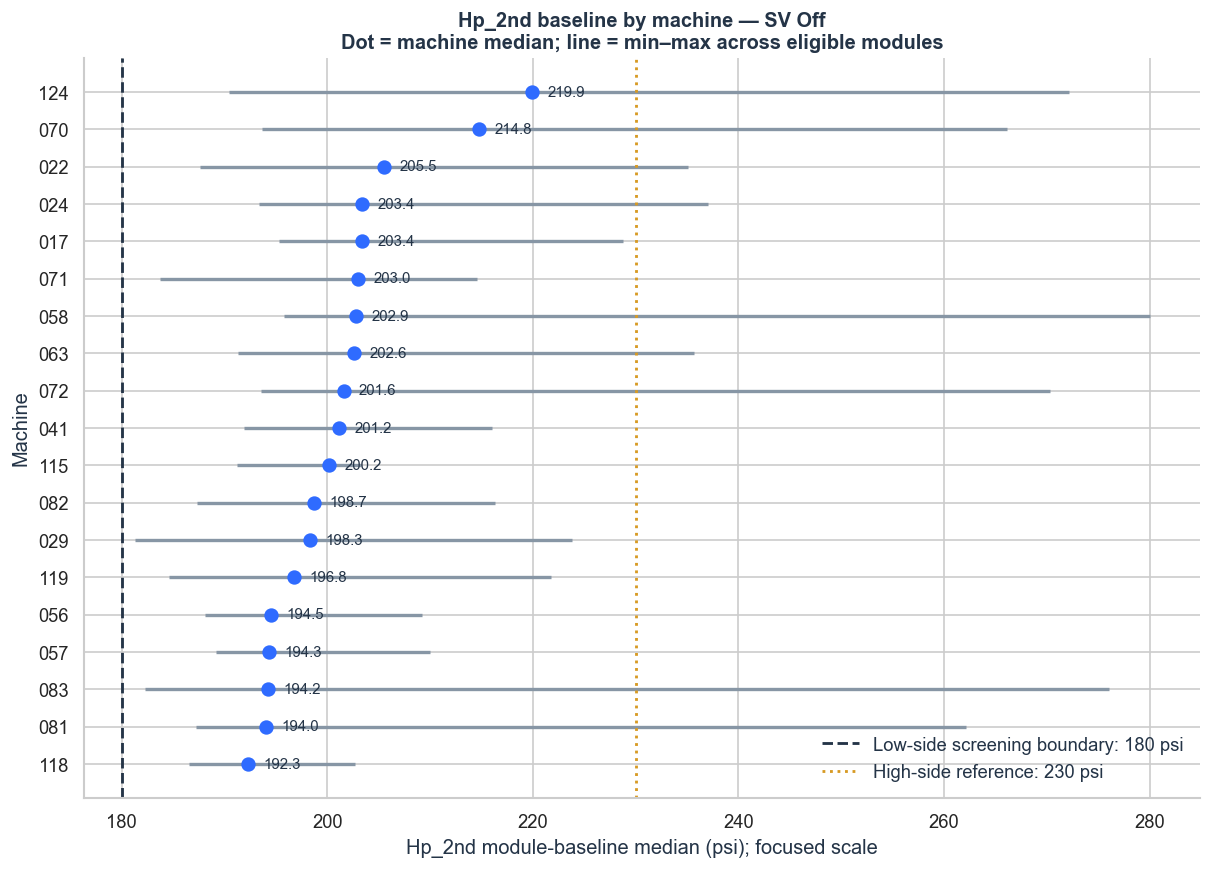

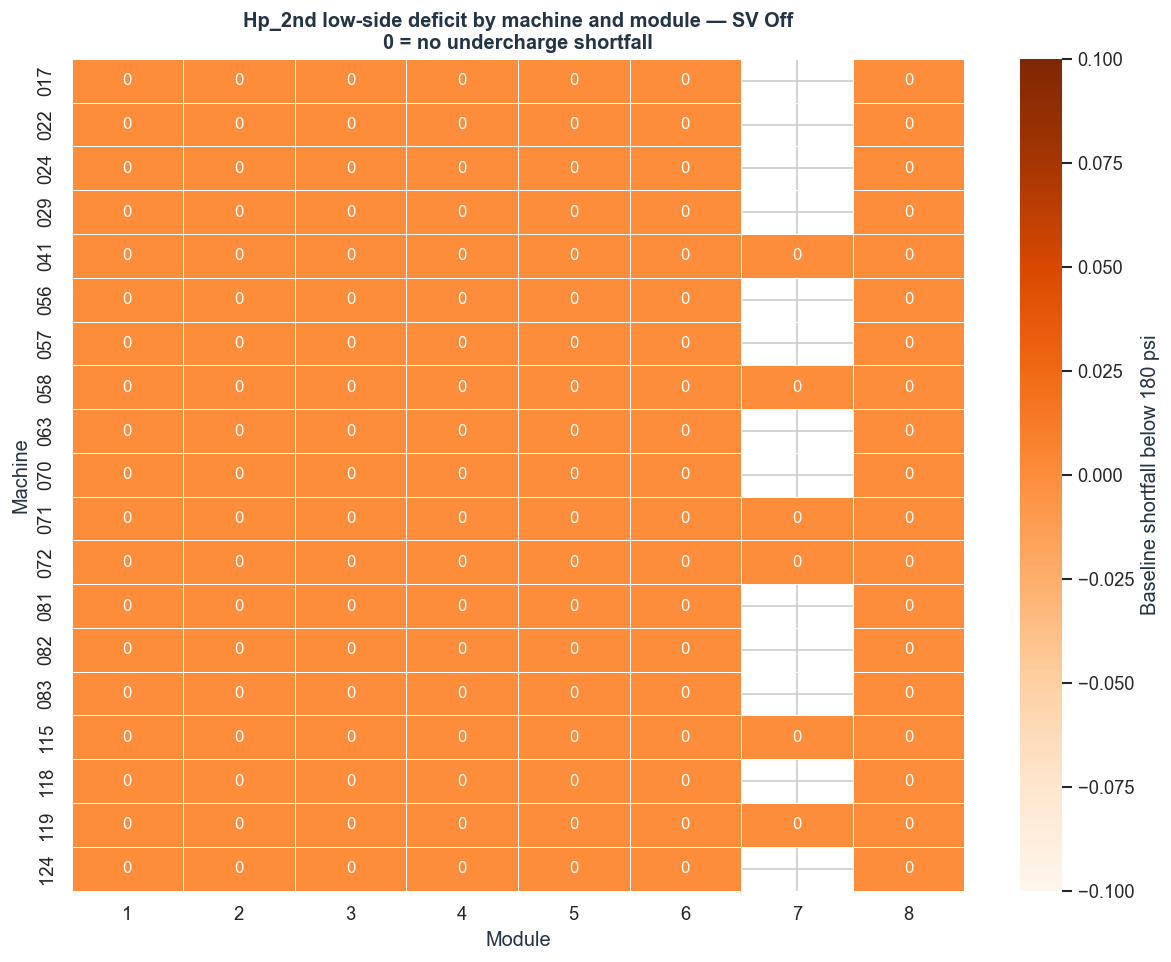

In [9]:
HP2_LOW_GUARDRAIL_PSI = 180.0
HP2_HIGH_REFERENCE_PSI = 230.0

hp2_off = baseline[(baseline["sv"] == "Off") & baseline["sufficient_baseline"]].copy()
hp2_machine = (
    hp2_off.groupby("machine_number", as_index=False)
    .agg(
        hp2_median=("hp2_median", "median"),
        module_min=("hp2_median", "min"),
        module_max=("hp2_median", "max"),
        eligible_modules=("module", "nunique"),
    )
    .sort_values("hp2_median")
)

fig, ax = plt.subplots(figsize=(12, 8))
y = np.arange(len(hp2_machine))
for i, row in hp2_machine.reset_index(drop=True).iterrows():
    below = row["hp2_median"] < HP2_LOW_GUARDRAIL_PSI
    color = PALETTE["orange"] if below else PALETTE["blue"]
    marker = "s" if below else "o"
    ax.hlines(i, row["module_min"], row["module_max"], color=PALETTE["grey"], lw=2)
    ax.scatter(row["hp2_median"], i, color=color, marker=marker, s=58, zorder=3)
    label_x = row["hp2_median"] - 1.5 if below else row["hp2_median"] + 1.5
    label_ha = "right" if below else "left"
    ax.text(label_x, i, f'{row["hp2_median"]:.1f}', va="center", ha=label_ha, fontsize=9)
ax.axvline(HP2_LOW_GUARDRAIL_PSI, color=PALETTE["ink"], ls="--", lw=1.7,
           label="Low-side screening boundary: 180 psi")
ax.axvline(HP2_HIGH_REFERENCE_PSI, color=PALETTE["gold"], ls=":", lw=1.7,
           label="High-side reference: 230 psi")
ax.set_yticks(y, hp2_machine["machine_number"])
ax.set_xlabel("Hp_2nd module-baseline median (psi); focused scale")
ax.set_ylabel("Machine")
ax.set_title("Hp_2nd baseline by machine — SV Off\nDot = machine median; line = min–max across eligible modules")
ax.legend(frameon=False, loc="lower right")
sns.despine()
savefig("05b_hp2_machine_interval_sv_off.png")
plt.show()

hp2_off["low_deficit_psi"] = np.maximum(0, HP2_LOW_GUARDRAIL_PSI - hp2_off["hp2_median"])
deficit_heat = hp2_off.pivot(index="machine_number", columns="module", values="low_deficit_psi")
deficit_heat = deficit_heat.reindex(index=machines, columns=range(1, 9))
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    deficit_heat, cmap="Oranges", vmin=0, linewidths=.35, annot=True, fmt=".0f",
    cbar_kws={"label": "Baseline shortfall below 180 psi"}, ax=ax,
)
ax.set_title("Hp_2nd low-side deficit by machine and module — SV Off\n0 = no undercharge shortfall")
ax.set_xlabel("Module")
ax.set_ylabel("Machine")
savefig("05c_hp2_low_deficit_heatmap_sv_off.png")
plt.show()

**วิธีอ่าน:** สี่เหลี่ยมสีส้มหมายถึงค่ากลางของเครื่องต่ำกว่า 180 psi ส่วนวงกลมสีน้ำเงินหมายถึงค่ากลางไม่ต่ำกว่าเกณฑ์
อย่างไรก็ตาม ช่วง min–max ที่กว้างแสดงว่าต้องย้อนดูราย module ก่อนเสมอ และค่า deficit ยังไม่ใช่คำยืนยัน leak.
ใน heatmap ค่า `0` หมายถึงไม่ต่ำกว่า guardrail ส่วนช่องว่างหมายถึง baseline ที่เทียบเคียงได้มีไม่พอ.

# Phase 4 — Relationship analysis

## 4.1 Baseline level vs relationship

คำสองคำนี้ตอบคนละคำถาม:

- **Baseline level/range:** ค่านี้มักอยู่แถวไหนและแกว่งได้เท่าไร ภายใต้ `machine × module × SV × settled run state` เดียวกัน เช่น median, IQR และ P05–P95
- **Relationship:** เมื่อค่าหนึ่งเปลี่ยน ค่าอื่นมีแนวโน้มเปลี่ยนไปด้วยหรือไม่และไปทางใด เช่น Spearman correlation รวมถึง slope และ lag response

ดังนั้นสองเครื่องอาจมี pressure baseline ใกล้กันแต่ relationship ต่างกัน หรือ baseline ต่างกันแต่ relationship คล้ายกันก็ได้

> “ค่าปกติ” ใน notebook นี้หมายถึง **observed reference behavior ที่เกิดซ้ำบ่อยหลัง qualification ข้อมูล** ไม่ใช่คำยืนยันจากช่างว่าเครื่อง healthy 100%

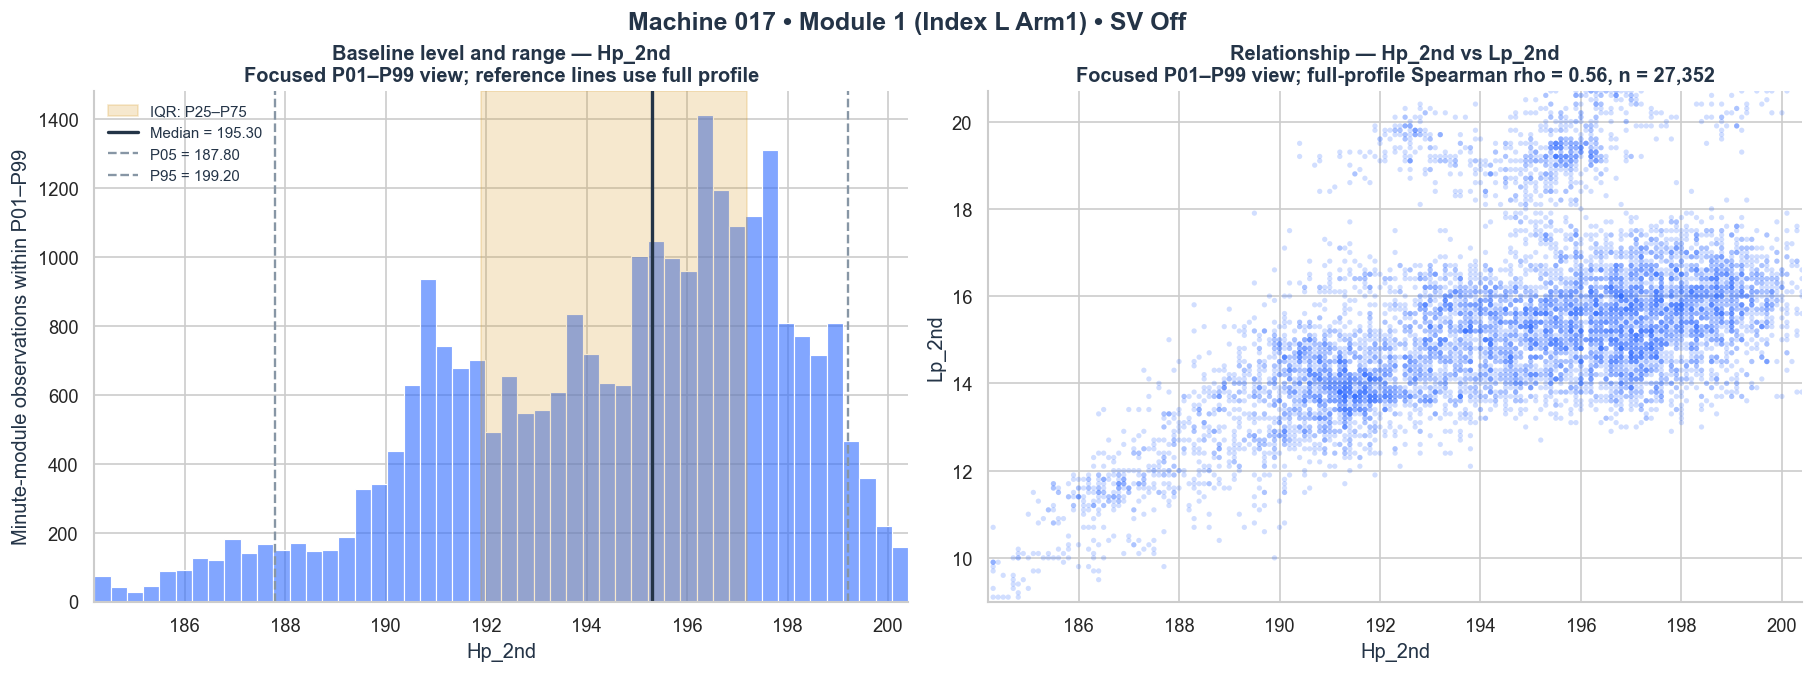

Meaning,Question answered,Result for selected profile
Observed baseline,Hp_2nd อยู่แถวไหนและกระจายเท่าไร,Median 195.30; IQR 191.90–197.20; P05–P95 187.80–199.20
Relationship,Hp_2nd กับ Lp_2nd เปลี่ยนร่วมกันแค่ไหน,Spearman rho 0.56; correlation is not causation


### Interactive: เลือกเครื่อง, module, SV และคู่ข้อมูล

interactive(children=(Dropdown(description='Machine', options=('017', '022', '024', '029', '041', '056', '057'…

In [10]:
relationship_features = ["hp1", "lp1", "hp2", "lp2", "valve", "temphi", "templo"]
relationship_labels = {
    "hp1": "Hp_1st", "lp1": "Lp_1st", "hp2": "Hp_2nd", "lp2": "Lp_2nd",
    "valve": "Valve", "temphi": "TempHigh", "templo": "TempLow",
}

def explain_normal_and_relationship(
    machine="017", module=1, sv="Off", feature_x="hp2", feature_y="lp2", save=False
):
    profile = (
        minute.filter(
            (pl.col("machine_number") == machine)
            & (pl.col("module") == int(module))
            & pl.col("baseline_eligible")
            & (pl.col("sv") == sv)
        )
        .select(relationship_features)
        .to_pandas()
        .dropna(subset=[feature_x, feature_y])
    )
    if len(profile) < 50:
        display(Markdown(
            f"ข้อมูลไม่พอสำหรับ Machine {machine}, Module {module}, SV {sv}: n={len(profile):,}"
        ))
        return

    q01, q05, q25, median, q75, q95, q99 = profile[feature_x].quantile(
        [.01, .05, .25, .50, .75, .95, .99]
    )
    y01, y99 = profile[feature_y].quantile([.01, .99])
    rho = profile[[feature_x, feature_y]].corr(method="spearman").iloc[0, 1]
    focused_pair = profile[
        profile[feature_x].between(q01, q99) & profile[feature_y].between(y01, y99)
    ]
    sample_n = min(8000, len(focused_pair))
    sample = focused_pair.sample(n=sample_n, random_state=42) if len(focused_pair) > sample_n else focused_pair

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)

    focused_distribution = profile.loc[
        profile[feature_x].between(q01, q99), feature_x
    ]
    sns.histplot(focused_distribution, bins=50, color=PALETTE["blue"], alpha=.6, ax=axes[0])
    axes[0].axvspan(q25, q75, color=PALETTE["gold"], alpha=.22, label="IQR: P25–P75")
    axes[0].axvline(median, color=PALETTE["ink"], lw=2, label=f"Median = {median:.2f}")
    axes[0].axvline(q05, color=PALETTE["grey"], lw=1.4, ls="--", label=f"P05 = {q05:.2f}")
    axes[0].axvline(q95, color=PALETTE["grey"], lw=1.4, ls="--", label=f"P95 = {q95:.2f}")
    axes[0].set_xlim(q01, q99)
    axes[0].set_title(
        f"Baseline level and range — {relationship_labels[feature_x]}\n"
        "Focused P01–P99 view; reference lines use full profile"
    )
    axes[0].set_xlabel(relationship_labels[feature_x])
    axes[0].set_ylabel("Minute-module observations within P01–P99")
    axes[0].legend(frameon=False, fontsize=9)

    axes[1].scatter(
        sample[feature_x], sample[feature_y], s=10, alpha=.22,
        color=PALETTE["blue"], edgecolors="none", rasterized=True,
    )
    axes[1].set_title(
        f"Relationship — {relationship_labels[feature_x]} vs {relationship_labels[feature_y]}\n"
        f"Focused P01–P99 view; full-profile Spearman rho = {rho:.2f}, n = {len(profile):,}"
    )
    axes[1].set_xlabel(relationship_labels[feature_x])
    axes[1].set_ylabel(relationship_labels[feature_y])
    axes[1].set_xlim(q01, q99)
    axes[1].set_ylim(y01, y99)

    fig.suptitle(
        f"Machine {machine} • Module {module} ({module_names[int(module)]}) • SV {sv}",
        fontsize=15, fontweight="bold",
    )
    sns.despine()
    if save:
        savefig(f"06a_normal_vs_relationship_{machine}_m{module}_{sv.lower()}.png")
    plt.show()

    summary_table = pd.DataFrame({
        "Meaning": ["Observed baseline", "Relationship"],
        "Question answered": [
            f"{relationship_labels[feature_x]} อยู่แถวไหนและกระจายเท่าไร",
            f"{relationship_labels[feature_x]} กับ {relationship_labels[feature_y]} เปลี่ยนร่วมกันแค่ไหน",
        ],
        "Result for selected profile": [
            f"Median {median:.2f}; IQR {q25:.2f}–{q75:.2f}; P05–P95 {q05:.2f}–{q95:.2f}",
            f"Spearman rho {rho:.2f}; correlation is not causation",
        ],
    })
    display(summary_table.style.hide(axis="index"))

explain_normal_and_relationship("017", 1, "Off", "hp2", "lp2", save=True)

if widgets is not None:
    display(Markdown("### Interactive: เลือกเครื่อง, module, SV และคู่ข้อมูล"))
    widgets.interact(
        explain_normal_and_relationship,
        machine=widgets.Dropdown(options=machines, value=machines[0], description="Machine"),
        module=widgets.Dropdown(
            options=[(f"{i}: {module_names[i]}", i) for i in range(1, 9)],
            value=1, description="Module",
        ),
        sv=widgets.Dropdown(options=["Off", "On"], value="Off", description="SV"),
        feature_x=widgets.Dropdown(options=relationship_features, value="hp2", description="Baseline"),
        feature_y=widgets.Dropdown(options=relationship_features, value="lp2", description="Related"),
        save=widgets.fixed(False),
    )

**วิธีใช้กับ ML:** robust z-score ตอบว่าค่าปัจจุบันห่างจาก baseline ของ profile ตัวเองเพียงใด ส่วน pressure differential, rolling slope, correlation และ lag response ใช้ตรวจว่ารูปแบบการทำงานร่วมกันเปลี่ยนจากเดิมหรือไม่ ต้องพิจารณาสองส่วนร่วมกัน

## 4.2 Correlation รายเครื่องและราย module

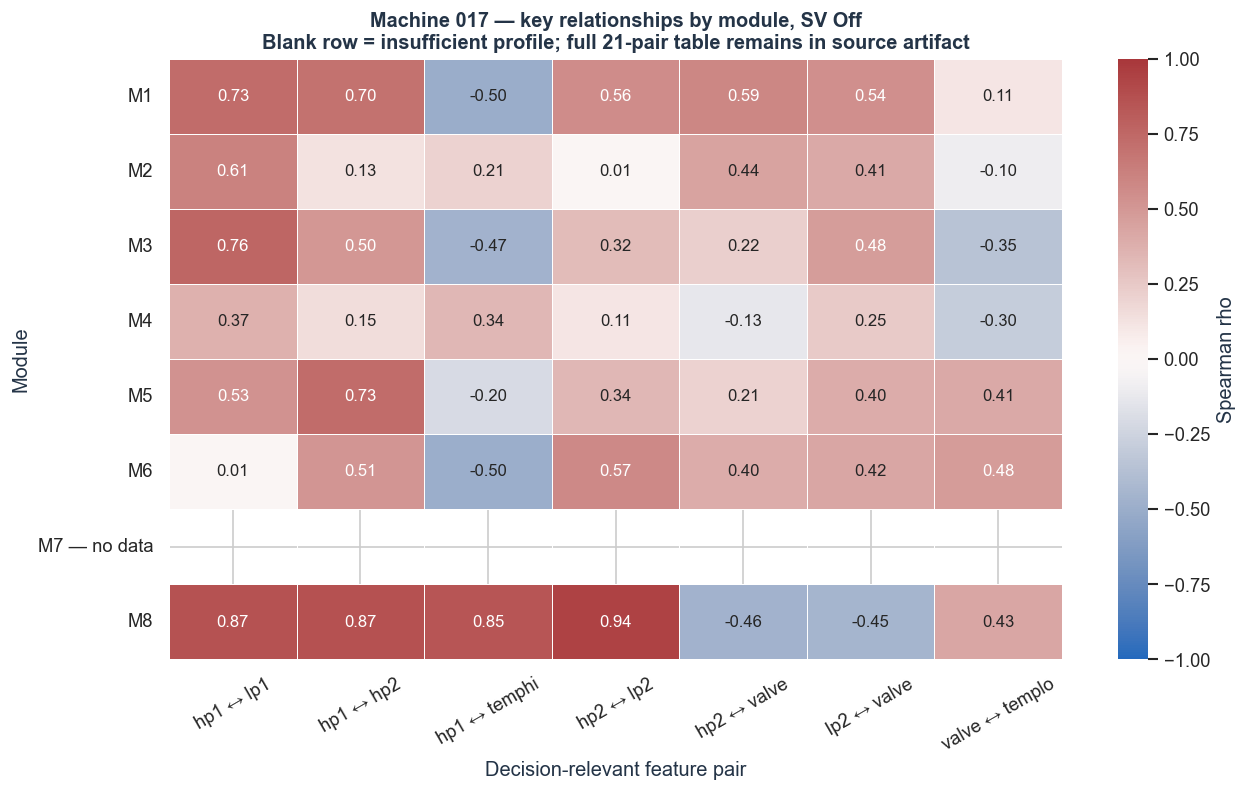

### Interactive relationship heatmap

interactive(children=(Dropdown(description='Machine', options=('017', '022', '024', '029', '041', '056', '057'…

In [11]:
def pair_name(row):
    return f"{row['feature_x']} ↔ {row['feature_y']}"

correlations["pair"] = correlations.apply(pair_name, axis=1)
presentation_pairs = [
    "hp1 ↔ lp1", "hp1 ↔ hp2", "hp1 ↔ temphi",
    "hp2 ↔ lp2", "hp2 ↔ valve", "lp2 ↔ valve", "valve ↔ templo",
]

def plot_machine_correlations(machine="017", sv="Off", save=False):
    part = correlations[(correlations["machine_number"] == machine) & (correlations["sv"] == sv)].copy()
    heat = part.pivot(index="module", columns="pair", values="spearman_rho")
    heat = heat.reindex(index=range(1, 9), columns=presentation_pairs)
    fig, ax = plt.subplots(figsize=(12, 6.5))
    sns.heatmap(
        heat, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
        linewidths=.4, cbar_kws={"label": "Spearman rho"}, ax=ax,
    )
    row_labels = [f"M{i}" + (" — no data" if heat.loc[i].isna().all() else "") for i in heat.index]
    ax.set_yticklabels(row_labels, rotation=0)
    ax.set_title(
        f"Machine {machine} — key relationships by module, SV {sv}\n"
        "Blank row = insufficient profile; full 21-pair table remains in source artifact"
    )
    ax.set_xlabel("Decision-relevant feature pair")
    ax.set_ylabel("Module")
    ax.tick_params(axis="x", rotation=30)
    if save:
        savefig(f"06_machine_{machine}_correlations_{sv.lower()}.png")
    plt.show()

plot_machine_correlations("017", "Off", save=True)

if widgets is not None:
    display(Markdown("### Interactive relationship heatmap"))
    widgets.interact(
        plot_machine_correlations,
        machine=widgets.Dropdown(options=machines, value=machines[0], description="Machine"),
        sv=widgets.Dropdown(options=["Off", "On"], value="Off", description="SV"),
        save=widgets.fixed(False),
    )

ค่าใกล้ `+1` หมายถึงเพิ่ม/ลดไปในทิศเดียวกัน ค่าใกล้ `-1` หมายถึงสวนทาง และค่าใกล้ `0` หมายถึงไม่มีความสัมพันธ์แบบอันดับที่ชัดเจนใน state นั้น การเห็น correlation สูงยังไม่เพียงพอจะบอกว่า feature หนึ่งเป็นสาเหตุของอีก feature

## 4.3 Machine × module drill-down

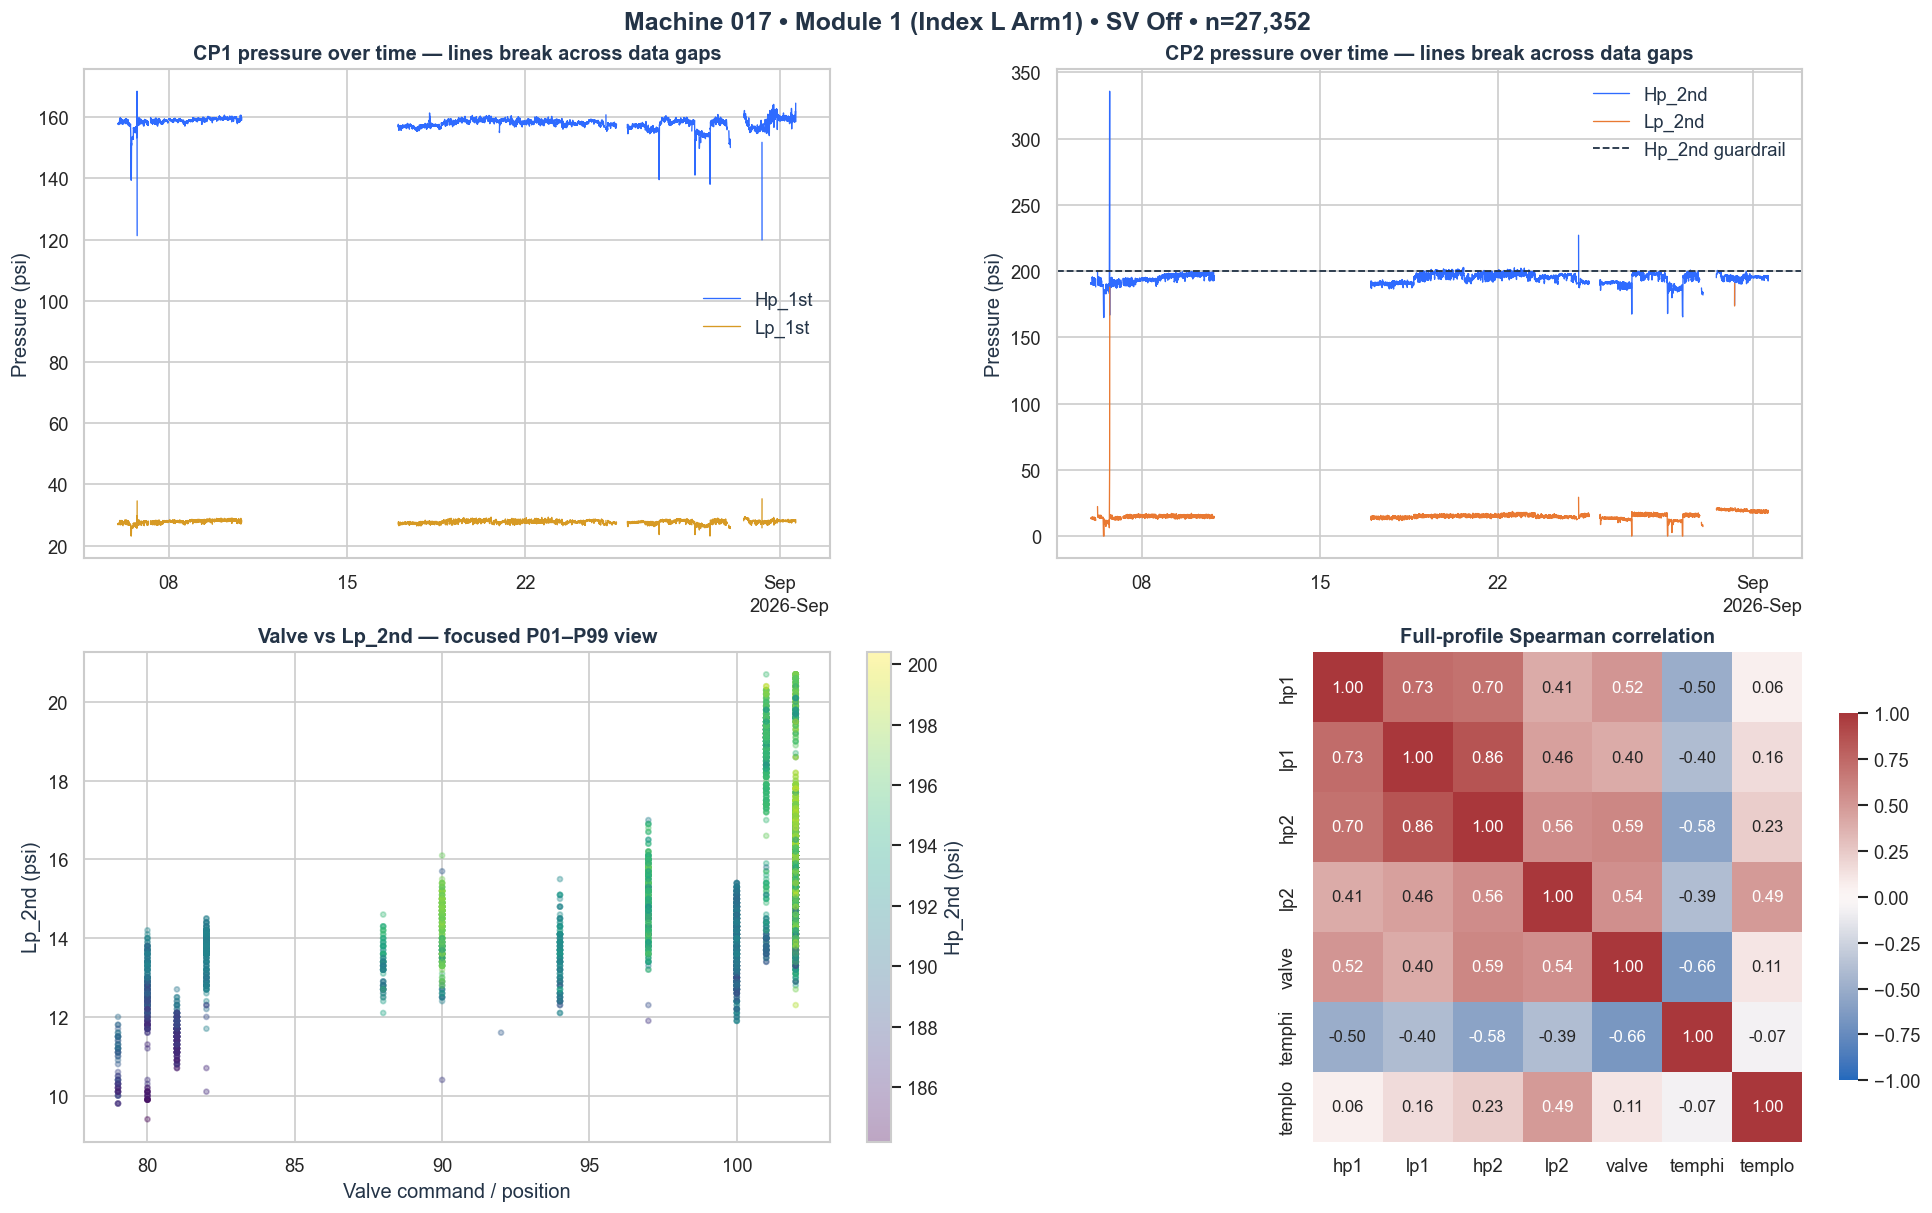

### Interactive machine × module drill-down

interactive(children=(Dropdown(description='Machine', options=('017', '022', '024', '029', '041', '056', '057'…

In [12]:
detail_columns = ["minute", "hp1", "lp1", "hp2", "lp2", "valve", "temphi", "templo", "sv"]

def get_detail(machine, module, sv):
    return (
        minute.filter(
            (pl.col("machine_number") == machine) &
            (pl.col("module") == int(module)) &
            pl.col("baseline_eligible") &
            (pl.col("sv") == sv)
        )
        .select([c for c in detail_columns if c in minute.columns])
        .sort("minute")
        .to_pandas()
    )

def plot_machine_module_detail(machine="017", module=1, sv="Off", max_points=8000, save=False):
    p = get_detail(machine, module, sv)
    if p.empty:
        display(Markdown(f"ไม่มี baseline-eligible rows สำหรับ Machine {machine}, Module {module}, SV {sv}"))
        return
    if len(p) > max_points:
        sample_idx = np.linspace(0, len(p) - 1, max_points).astype(int)
        s = p.iloc[sample_idx].copy()
    else:
        s = p.copy()

    timeline = s.copy()
    typical_step = timeline["minute"].diff().median()
    gap_limit = max(pd.Timedelta(minutes=10), typical_step * 5)
    gap_rows = timeline["minute"].diff() > gap_limit
    timeline.loc[gap_rows, ["hp1", "lp1", "hp2", "lp2"]] = np.nan

    fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)
    axes[0, 0].plot(timeline["minute"], timeline["hp1"], label="Hp_1st", color=PALETTE["blue"], lw=.8)
    axes[0, 0].plot(timeline["minute"], timeline["lp1"], label="Lp_1st", color=PALETTE["gold"], lw=.8)
    axes[0, 0].set_title("CP1 pressure over time — lines break across data gaps")
    axes[0, 0].set_ylabel("Pressure (psi)")
    axes[0, 0].legend(frameon=False)

    axes[0, 1].plot(timeline["minute"], timeline["hp2"], label="Hp_2nd", color=PALETTE["blue"], lw=.8)
    axes[0, 1].plot(timeline["minute"], timeline["lp2"], label="Lp_2nd", color=PALETTE["orange"], lw=.8)
    axes[0, 1].axhline(200, color=PALETTE["ink"], ls="--", lw=1.1, label="Hp_2nd guardrail")
    axes[0, 1].set_title("CP2 pressure over time — lines break across data gaps")
    axes[0, 1].set_ylabel("Pressure (psi)")
    axes[0, 1].legend(frameon=False)

    for ax in axes[0, :]:
        locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    q = p[["valve", "lp2", "hp2"]].dropna().copy()
    bounds = q.quantile([.01, .99])
    focused = q[
        q["valve"].between(bounds.loc[.01, "valve"], bounds.loc[.99, "valve"])
        & q["lp2"].between(bounds.loc[.01, "lp2"], bounds.loc[.99, "lp2"])
        & q["hp2"].between(bounds.loc[.01, "hp2"], bounds.loc[.99, "hp2"])
    ]
    if len(focused) > max_points:
        focused = focused.sample(max_points, random_state=42)
    sc = axes[1, 0].scatter(
        focused["valve"], focused["lp2"], c=focused["hp2"], s=9, alpha=.35,
        cmap="viridis", vmin=bounds.loc[.01, "hp2"], vmax=bounds.loc[.99, "hp2"], rasterized=True,
    )
    axes[1, 0].set_title("Valve vs Lp_2nd — focused P01–P99 view")
    axes[1, 0].set_xlabel("Valve command / position")
    axes[1, 0].set_ylabel("Lp_2nd (psi)")
    fig.colorbar(sc, ax=axes[1, 0], label="Hp_2nd (psi)")

    corr_cols = ["hp1", "lp1", "hp2", "lp2", "valve", "temphi", "templo"]
    corr = p[corr_cols].corr(method="spearman")
    sns.heatmap(corr, ax=axes[1, 1], cmap="vlag", center=0, vmin=-1, vmax=1,
                annot=True, fmt=".2f", square=True, cbar_kws={"shrink": .75})
    axes[1, 1].set_title("Full-profile Spearman correlation")

    fig.suptitle(
        f"Machine {machine} • Module {module} ({module_names[int(module)]}) • SV {sv} • n={len(p):,}",
        fontsize=15, fontweight="bold",
    )
    if save:
        savefig(f"07_detail_{machine}_m{module}_{sv.lower()}.png")
    plt.show()

plot_machine_module_detail("017", 1, "Off", save=True)

if widgets is not None:
    display(Markdown("### Interactive machine × module drill-down"))
    widgets.interact(
        plot_machine_module_detail,
        machine=widgets.Dropdown(options=machines, value=machines[0], description="Machine"),
        module=widgets.Dropdown(options=[(f"{i}: {module_names[i]}", i) for i in range(1, 9)], value=1, description="Module"),
        sv=widgets.Dropdown(options=["Off", "On"], value="Off", description="SV"),
        max_points=widgets.fixed(8000),
        save=widgets.fixed(False),
    )

# Phase 5 — Drift and service-epoch analysis

## 5.1 Daily trends — ดู drift ราย module โดยไม่รวม SV

ใช้ small multiples เพื่อให้แต่ละ module อ่านได้ชัดบนแกนเดียวกัน เส้นจะไม่ลากข้ามวันที่ไม่มีข้อมูล
และเมื่อดู `Hp_2nd` จะมีแถบ 180–230 psi เป็นช่วงอ้างอิงหน้างานสำหรับข้อมูลที่ผ่าน qualification

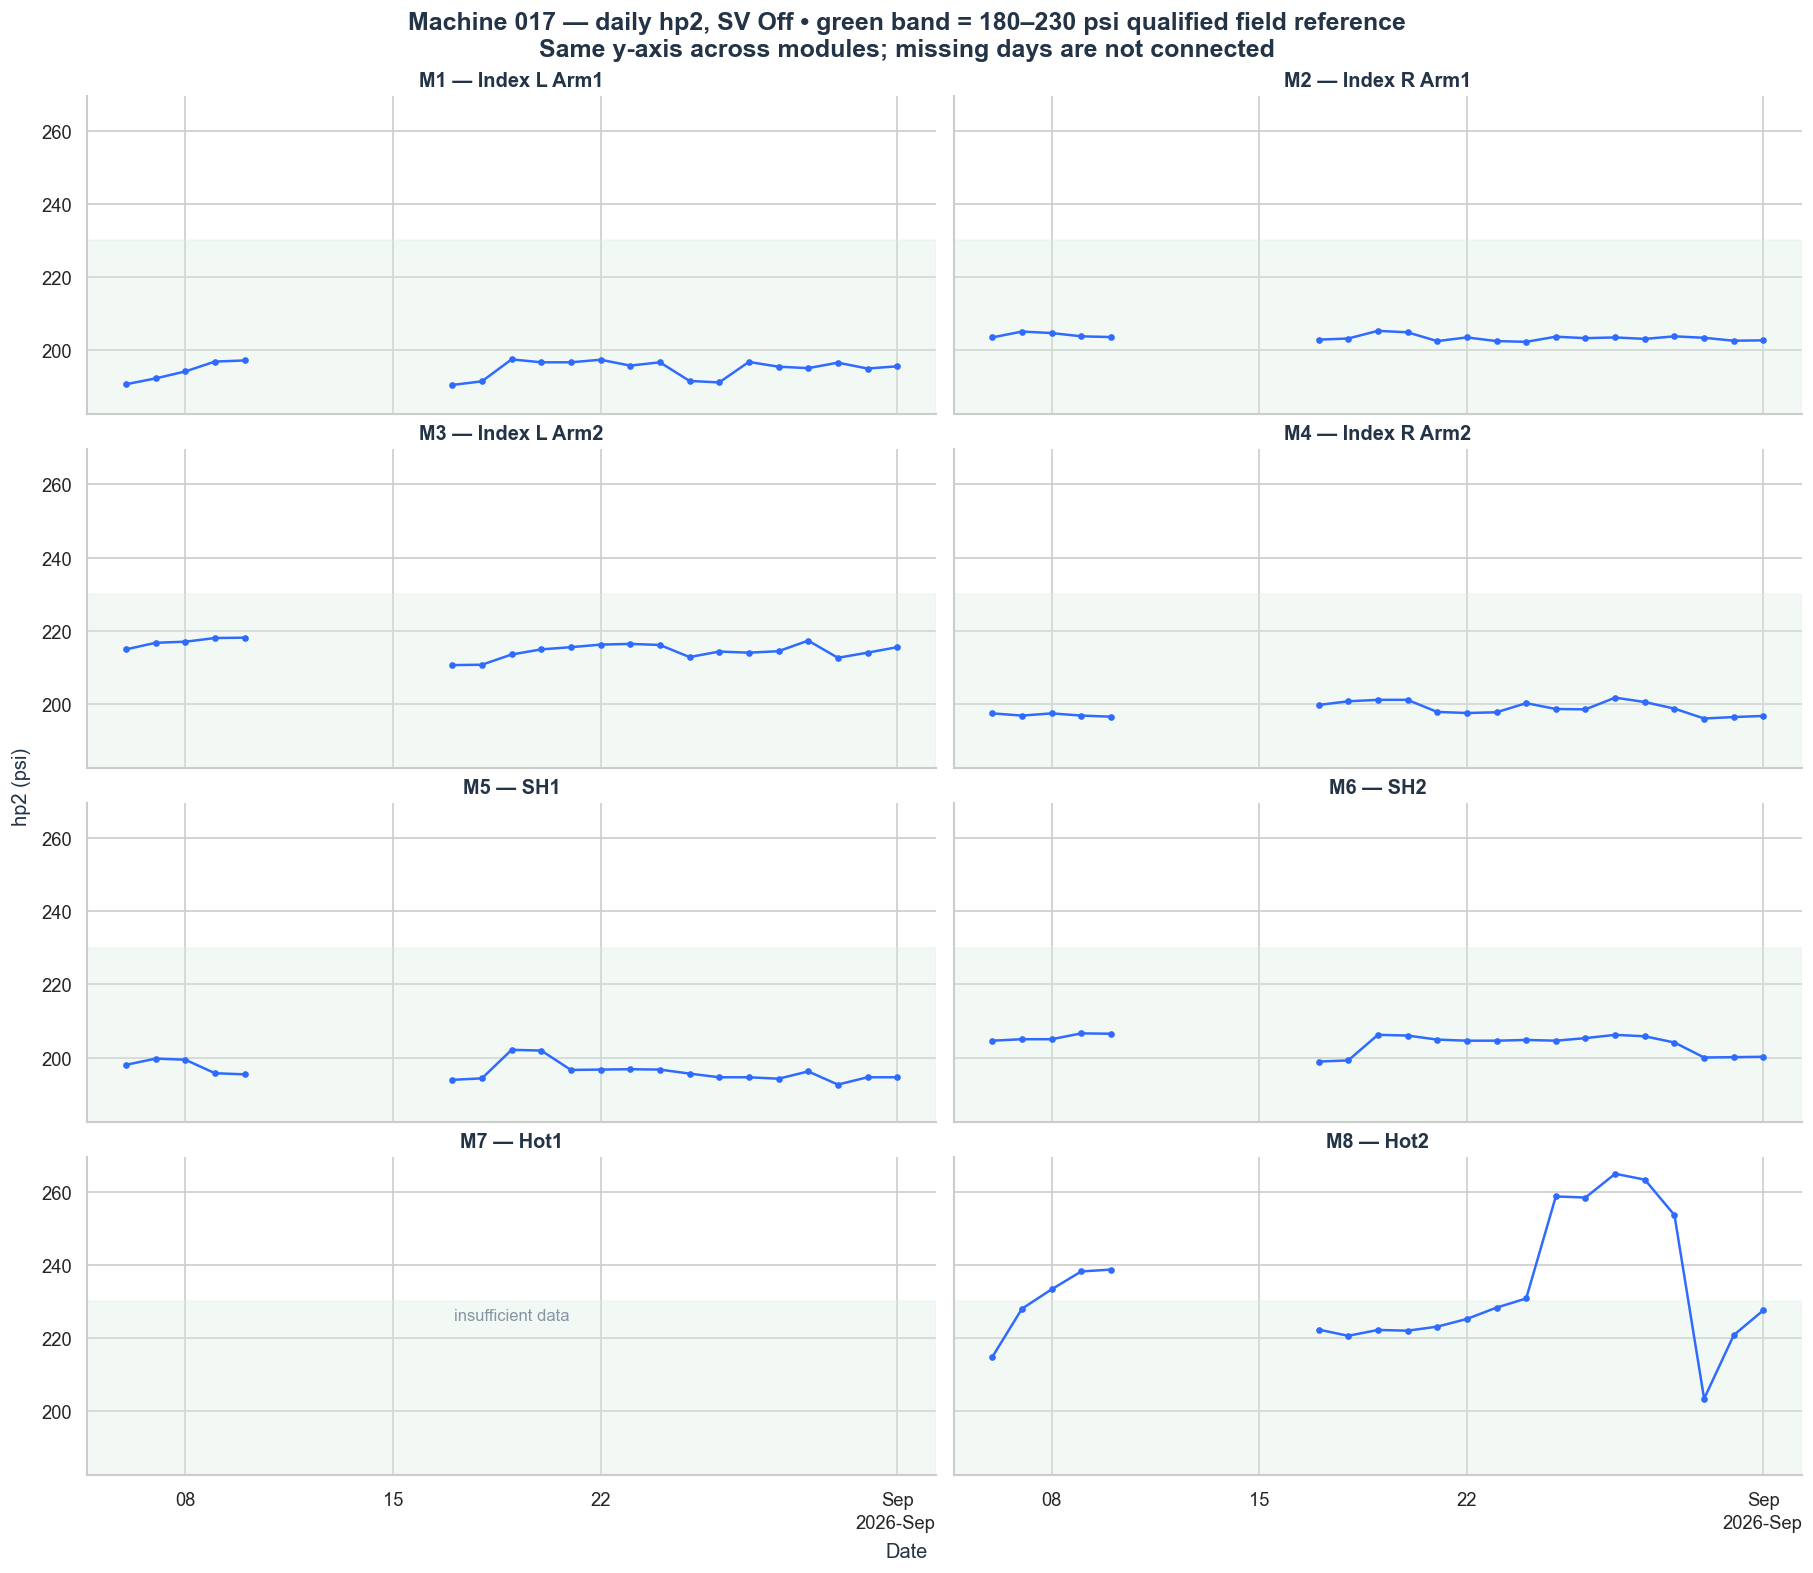

### Interactive daily trend — แยก SV เสมอ

interactive(children=(Dropdown(description='Machine', options=('017', '022', '024', '029', '041', '056', '057'…

In [13]:
daily_sv = (
    minute.filter(pl.col("baseline_eligible"))
    .with_columns(pl.col("minute").dt.date().alias("date"))
    .group_by(["machine_number", "module", "sv", "date"])
    .agg(
        pl.len().alias("n_minutes"),
        pl.col("hp2").median().alias("hp2_median"),
        pl.col("lp2").median().alias("lp2_median"),
        pl.col("valve").median().alias("valve_median"),
    )
    .sort(["machine_number", "module", "sv", "date"])
    .to_pandas()
)
daily_sv["date"] = pd.to_datetime(daily_sv["date"])

def plot_daily_trend(machine="017", metric="hp2_median", sv="Off", save=False):
    p = daily_sv[(daily_sv["machine_number"] == machine) & (daily_sv["sv"] == sv)].copy()
    fig, axes = plt.subplots(4, 2, figsize=(15, 13), sharex=True, sharey=True, constrained_layout=True)
    axes = axes.ravel()
    finite = p[metric].dropna()
    if finite.empty:
        display(Markdown(f"ไม่มี daily baseline สำหรับ Machine {machine}, SV {sv}"))
        plt.close(fig)
        return
    low, high = finite.quantile([.01, .99])
    pad = max((high - low) * .12, 1)
    for module, ax in zip(range(1, 9), axes):
        q = p[p["module"] == module].sort_values("date")
        ax.set_title(f"M{module} — {module_names[module]}")
        if q.empty:
            ax.text(.5, .5, "insufficient data", ha="center", va="center", transform=ax.transAxes,
                    color=PALETTE["grey"])
        else:
            # Plot each contiguous date segment separately so missing days are not visually bridged.
            q["segment"] = q["date"].diff().dt.days.fillna(1).gt(1).cumsum()
            for _, segment in q.groupby("segment"):
                ax.plot(segment["date"], segment[metric], marker="o", ms=3, lw=1.5,
                        color=PALETTE["blue"])
        if metric == "hp2_median":
            ax.axhspan(180, 230, color="#DCEFE4", alpha=.35)
        locator = mdates.AutoDateLocator(minticks=2, maxticks=5)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        ax.set_ylim(low - pad, high + pad)
        sns.despine(ax=ax)
    ylabel = metric.replace("_median", "") + (" (psi)" if metric.startswith(("hp", "lp")) else "")
    fig.supylabel(ylabel)
    fig.supxlabel("Date")
    guardrail_note = " • green band = 180–230 psi qualified field reference" if metric == "hp2_median" else ""
    fig.suptitle(
        f"Machine {machine} — daily {metric.replace('_median', '')}, SV {sv}{guardrail_note}\n"
        "Same y-axis across modules; missing days are not connected",
        fontsize=15, fontweight="bold",
    )
    if save:
        savefig(f"08_daily_{machine}_{metric}_{sv.lower()}.png")
    plt.show()

plot_daily_trend("017", "hp2_median", "Off", save=True)

if widgets is not None:
    display(Markdown("### Interactive daily trend — แยก SV เสมอ"))
    widgets.interact(
        plot_daily_trend,
        machine=widgets.Dropdown(options=machines, value=machines[0], description="Machine"),
        metric=widgets.Dropdown(
            options=[("Hp_2nd", "hp2_median"), ("Lp_2nd", "lp2_median"), ("Valve", "valve_median")],
            value="hp2_median", description="Metric",
        ),
        sv=widgets.Dropdown(options=["Off", "On"], value="Off", description="SV"),
        save=widgets.fixed(False),
    )

## 5.2 Positive pressure jumps — candidate สำหรับแบ่ง service epoch

หากมีการเติมน้ำยา ค่า `Hp_2nd` อาจกระโดดสูงขึ้นและ Baseline ก่อน–หลังไม่ควรถูกรวมกัน
เนื่องจากชุดข้อมูลนี้ไม่มี service log ที่ยืนยัน การกระโดดด้านล่างจึงเรียกว่า **candidate** เท่านั้น
และอาจเกิดจาก recipe/load/sensor/state coverage ที่เปลี่ยนได้.

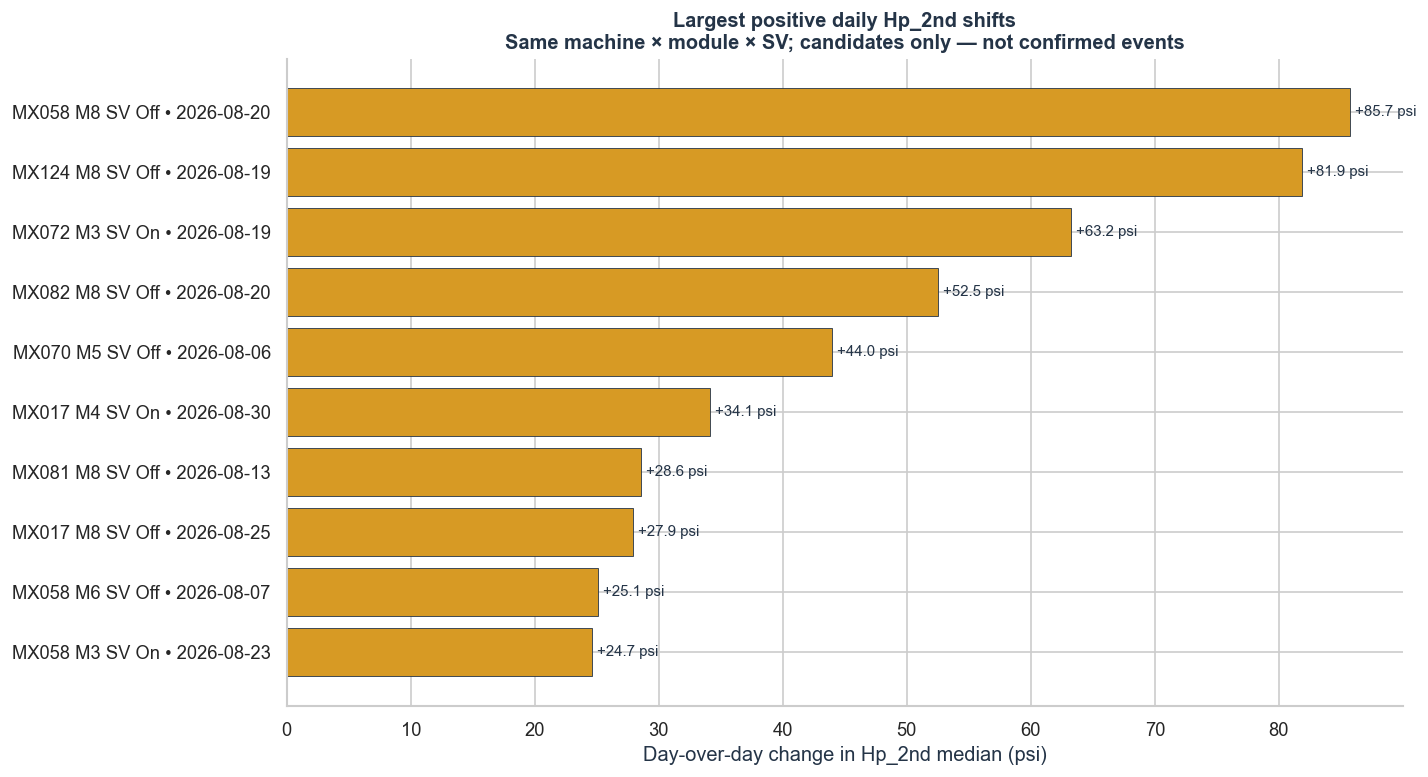

,machine_number,module,sv,date,hp2_median,hp2_daily_change,n_minutes
1546,058,8,Off,2026-08-20,282.60,85.70,1294
2796,124,8,Off,2026-08-19,279.35,81.90,160
1906,072,3,On,2026-08-19,257.50,63.20,104
2459,082,8,Off,2026-08-20,214.50,52.50,932
1694,070,5,Off,2026-08-06,268.30,44.00,1421
121,017,4,On,2026-08-30,244.30,34.10,355
2221,081,8,Off,2026-08-13,278.70,28.60,842
196,017,8,Off,2026-08-25,258.70,27.90,822
1468,058,6,Off,2026-08-07,295.70,25.10,1390
1396,058,3,On,2026-08-23,240.35,24.65,108


In [14]:
service_candidates = daily_sv.sort_values(["machine_number", "module", "sv", "date"]).copy()
service_candidates["hp2_daily_change"] = (
    service_candidates.groupby(["machine_number", "module", "sv"])["hp2_median"].diff()
)
service_candidates = service_candidates[
    (service_candidates["hp2_daily_change"] >= 15)
    & (service_candidates["n_minutes"] >= 60)
].copy()
service_candidates["label"] = (
    "MX" + service_candidates["machine_number"].astype(str)
    + " M" + service_candidates["module"].astype(str)
    + " SV " + service_candidates["sv"].astype(str)
    + " • " + service_candidates["date"].dt.strftime("%Y-%m-%d")
)
top_service_candidates = service_candidates.nlargest(10, "hp2_daily_change").sort_values("hp2_daily_change")

fig, ax = plt.subplots(figsize=(12, 7))
if top_service_candidates.empty:
    ax.text(.5, .5, "No daily positive jump >= 15 psi", ha="center", va="center", transform=ax.transAxes)
    ax.set_axis_off()
else:
    bars = ax.barh(top_service_candidates["label"], top_service_candidates["hp2_daily_change"],
                   color=PALETTE["gold"], edgecolor=PALETTE["ink"], linewidth=.5)
    ax.bar_label(bars, fmt="+%.1f psi", padding=3, fontsize=9)
    ax.set_xlabel("Day-over-day change in Hp_2nd median (psi)")
    ax.set_ylabel("")
    ax.set_title("Largest positive daily Hp_2nd shifts\nSame machine × module × SV; candidates only — not confirmed events")
    sns.despine()
savefig("09_service_epoch_candidates.png")
plt.show()

display(top_service_candidates[[
    "machine_number", "module", "sv", "date", "hp2_median", "hp2_daily_change", "n_minutes"
]].sort_values("hp2_daily_change", ascending=False).head(10))

# Phase 6 — Feature engineering and response analysis

## 6.1 Why the original one-minute lag looked weak

กราฟใช้ `|Spearman rho|` เพื่อสรุป **ความแรง** ของความสัมพันธ์ lag ที่ดีที่สุด จึงไม่แสดงทิศทางบวก/ลบ
ค่า median ที่อ่อนในข้อมูลระดับหนึ่งนาทีไม่ได้แปลว่า valve ไม่มีผล จึงต้องวัด event window จากข้อมูลหนึ่งวินาทีรอบ `ChangeValve` โดยตรง.

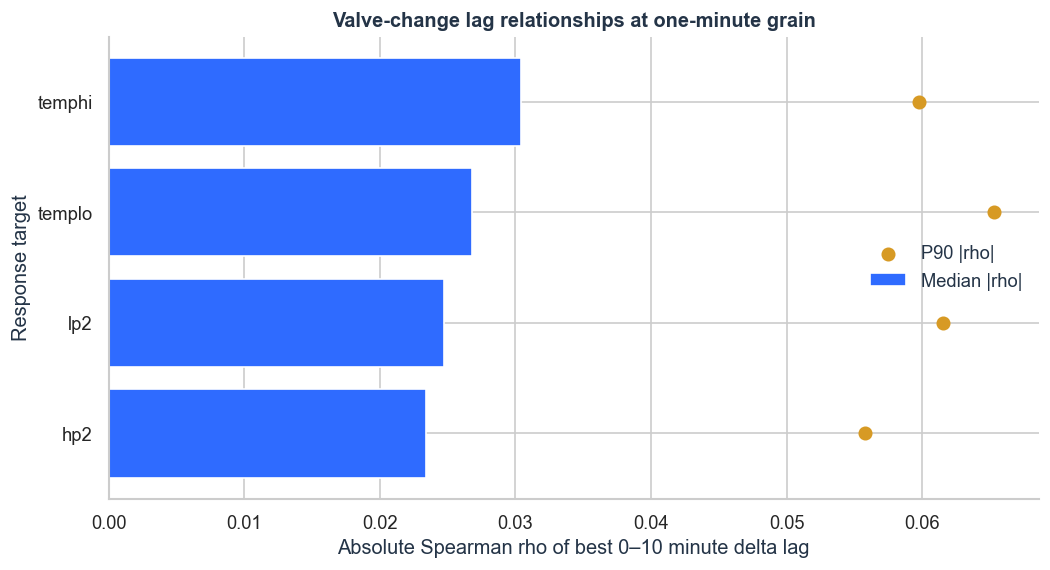

In [15]:
delta_lags = best_lags[best_lags["relationship_type"] == "delta"].copy()
lag_summary = (
    delta_lags.groupby("target")
    .agg(median_abs_rho=("abs_rho", "median"), p90_abs_rho=("abs_rho", lambda x: x.quantile(.9)),
         profiles=("abs_rho", "size"))
    .reset_index()
    .sort_values("median_abs_rho")
)

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(lag_summary))
ax.barh(y, lag_summary["median_abs_rho"], color=PALETTE["blue"], label="Median |rho|")
ax.scatter(lag_summary["p90_abs_rho"], y, color=PALETTE["gold"], s=55, label="P90 |rho|")
ax.set_yticks(y, lag_summary["target"])
ax.set_xlabel("Absolute Spearman rho of best 0–10 minute delta lag")
ax.set_ylabel("Response target")
ax.set_title("Valve-change lag relationships at one-minute grain")
ax.legend(frameon=False)
sns.despine()
savefig("09_lag_response_summary.png")
plt.show()

**ข้อสรุป:** ความสัมพันธ์ของ `ΔValve → Δpressure/temperature` ที่ aggregate ระดับ 1 นาทีค่อนข้างอ่อน จึงยังไม่ควรสรุปว่า valve ไม่มีผล ทางวิเคราะห์ถัดไปควรใช้ event windows จากข้อมูล 1 วินาทีรอบ `ChangeValve` เพื่อวัด response delay, gain และ settling โดยตรง

## 6.2 One-second event windows — เห็น response ที่ค่าเฉลี่ยหนึ่งนาทีซ่อนไว้

วิเคราะห์ข้อมูลดิบรอบจุดเริ่ม `ChangeValve` ตั้งแต่ **−30 ถึง +120 วินาที** หลังคัดเฉพาะ window ที่:

- ระบบ Run อย่างน้อย 98% และ SV ไม่เปลี่ยนสถานะตลอด window
- module เปิดก่อน event, ไม่มี `MValveHome`, module Off หรือ valve ติดลบ
- valve เปลี่ยนสุทธิอย่างน้อย 3 command units และไม่มีคำสั่งรอบใหม่ซ้อน

การจัดแนวตามเวลาเริ่ม event ทำให้เห็นลำดับ `Valve → pressure → temperature` ได้ชัดกว่าการเทียบแถวต่อนาที
แต่ยังเป็น **time-linked response** ไม่ใช่หลักฐานเชิงสาเหตุหรือการยืนยัน leak.


### ผลที่อ่านได้จากข้อมูลจริง

- ระยะห่าง timestamp ใกล้ **1 วินาที 98.55%**
- พบจุดเริ่ม ChangeValve 2,971 จุด และผ่าน qualification 243 events
- closing 241 events; opening 2 events — opening ยังน้อยเกินสรุป
- หลัง closing +60 วินาที: median ΔHp_2nd = -10.9 psi และ ΔLp_2nd = -12.7 psi
- หลัง closing +120 วินาที: median ΔTempHigh = -16.8 และ ΔTempLow = +8.3


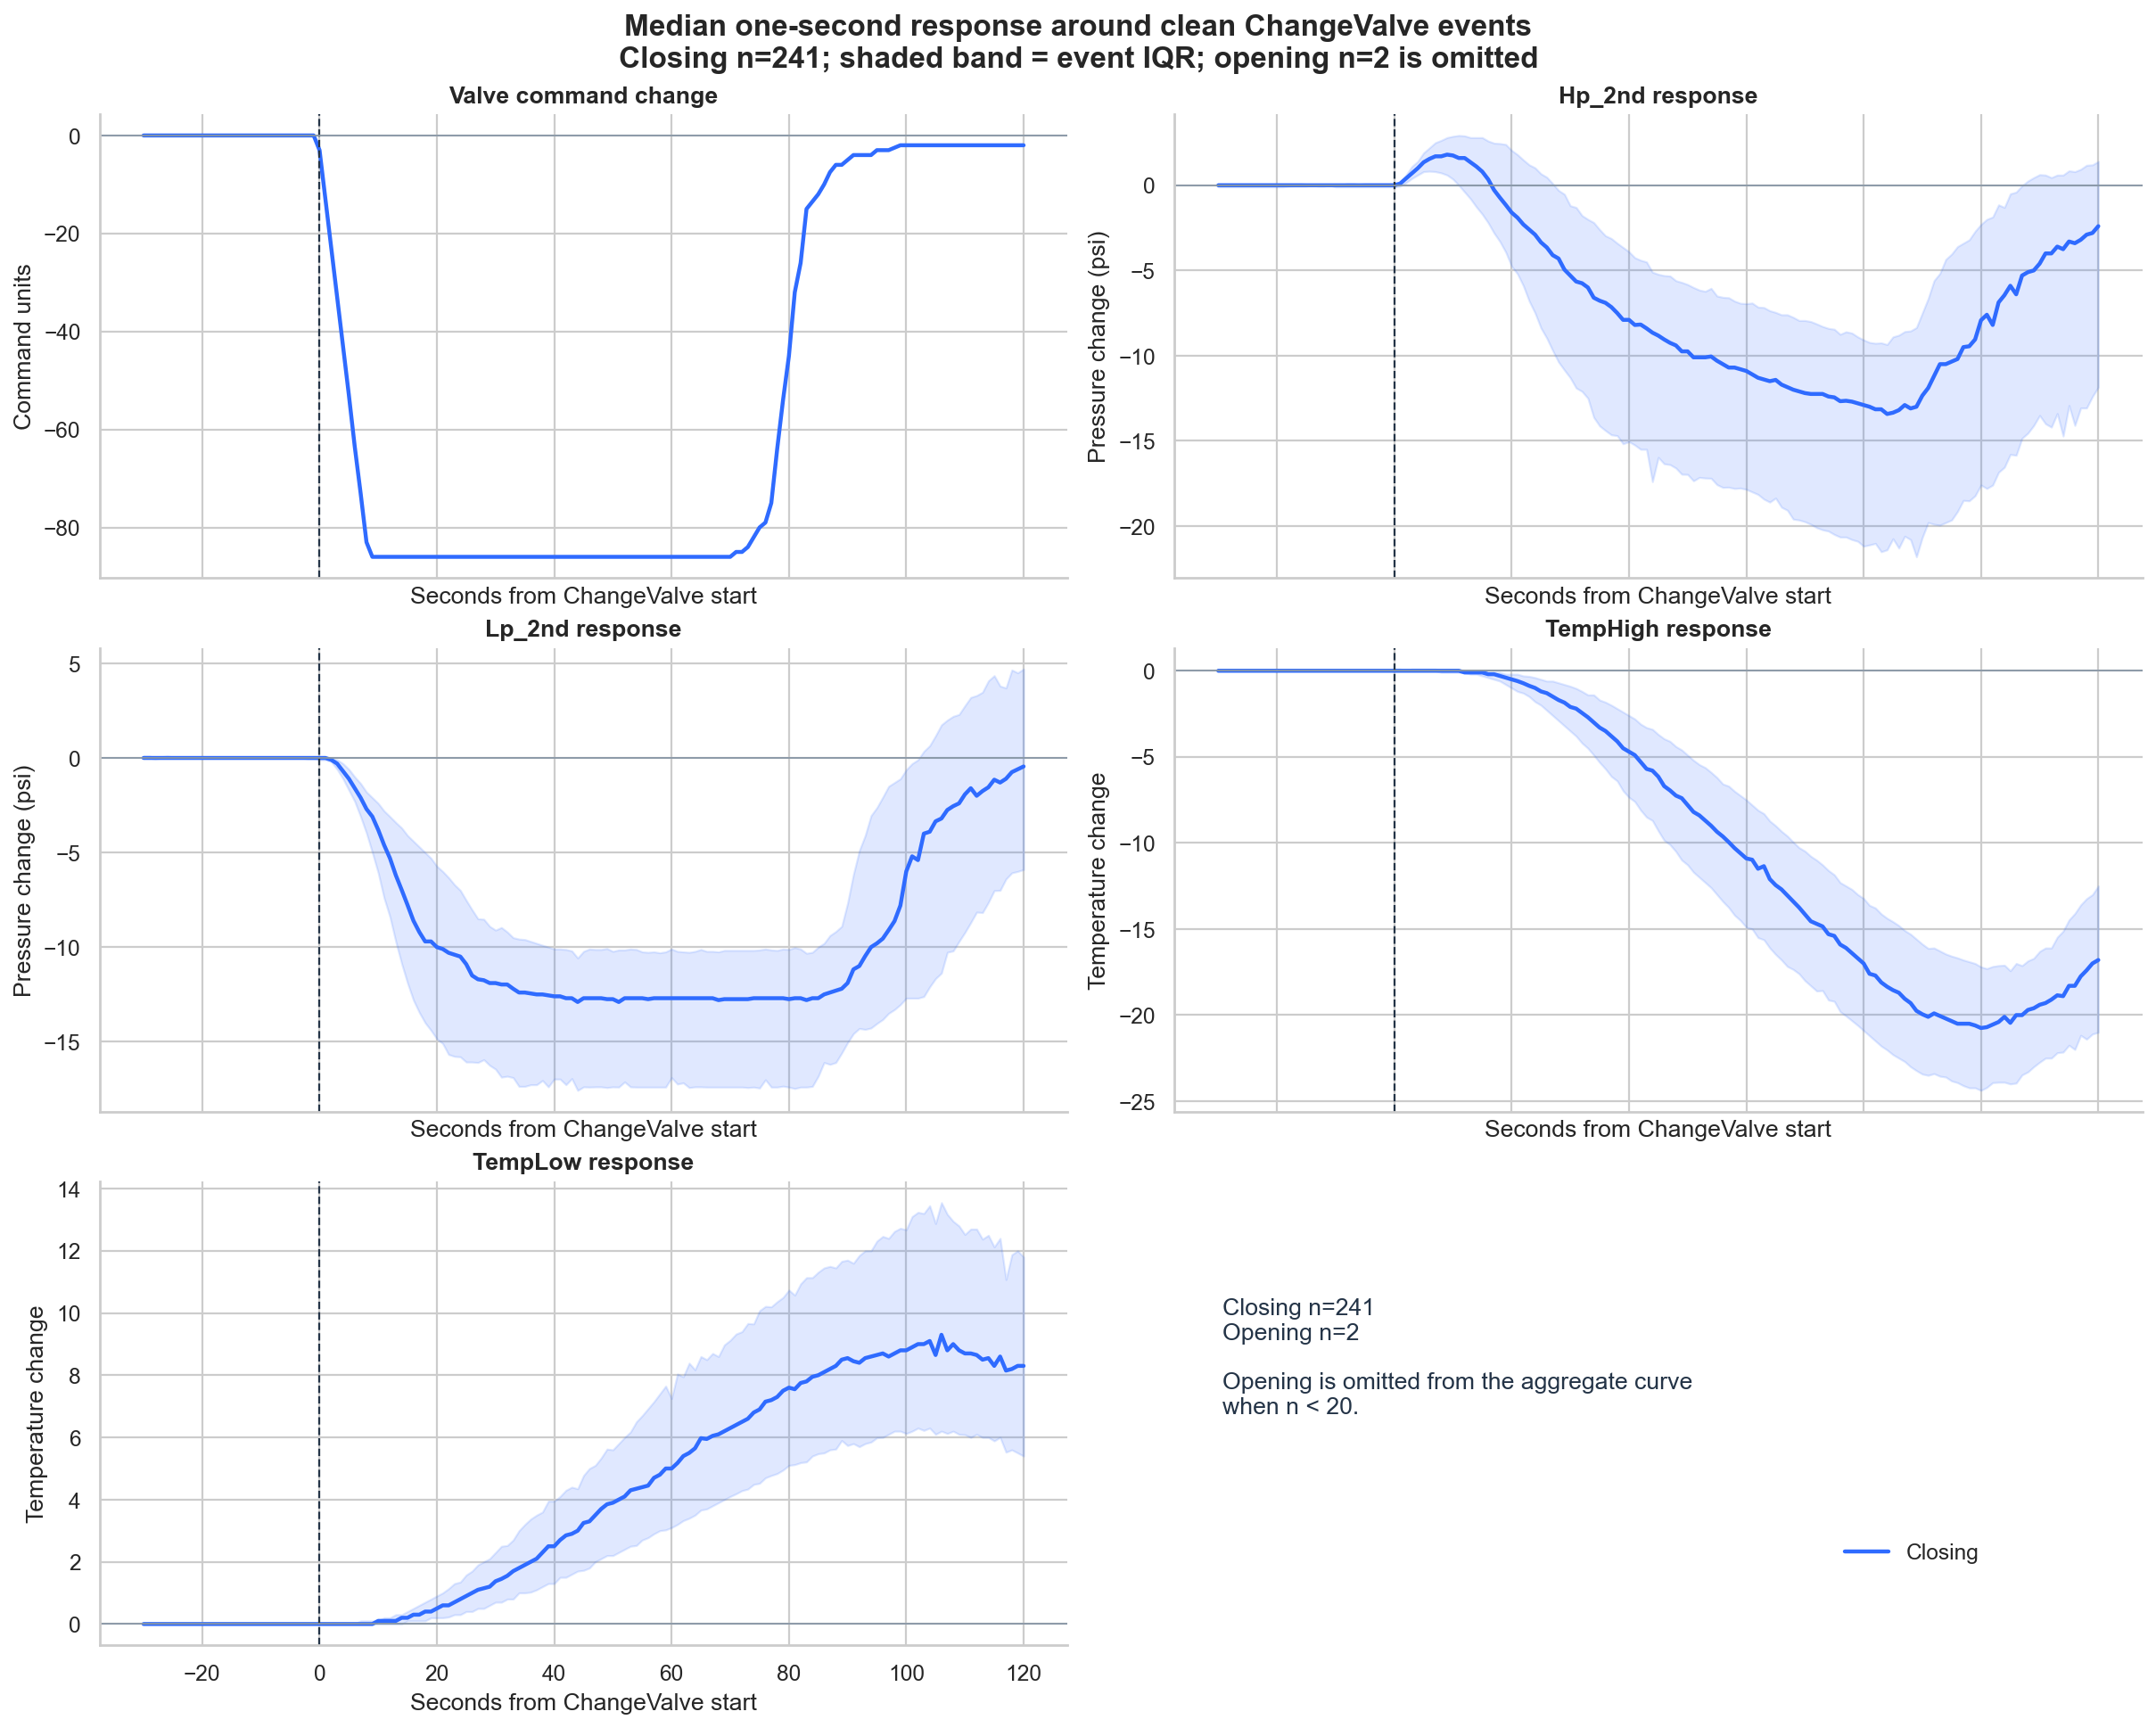

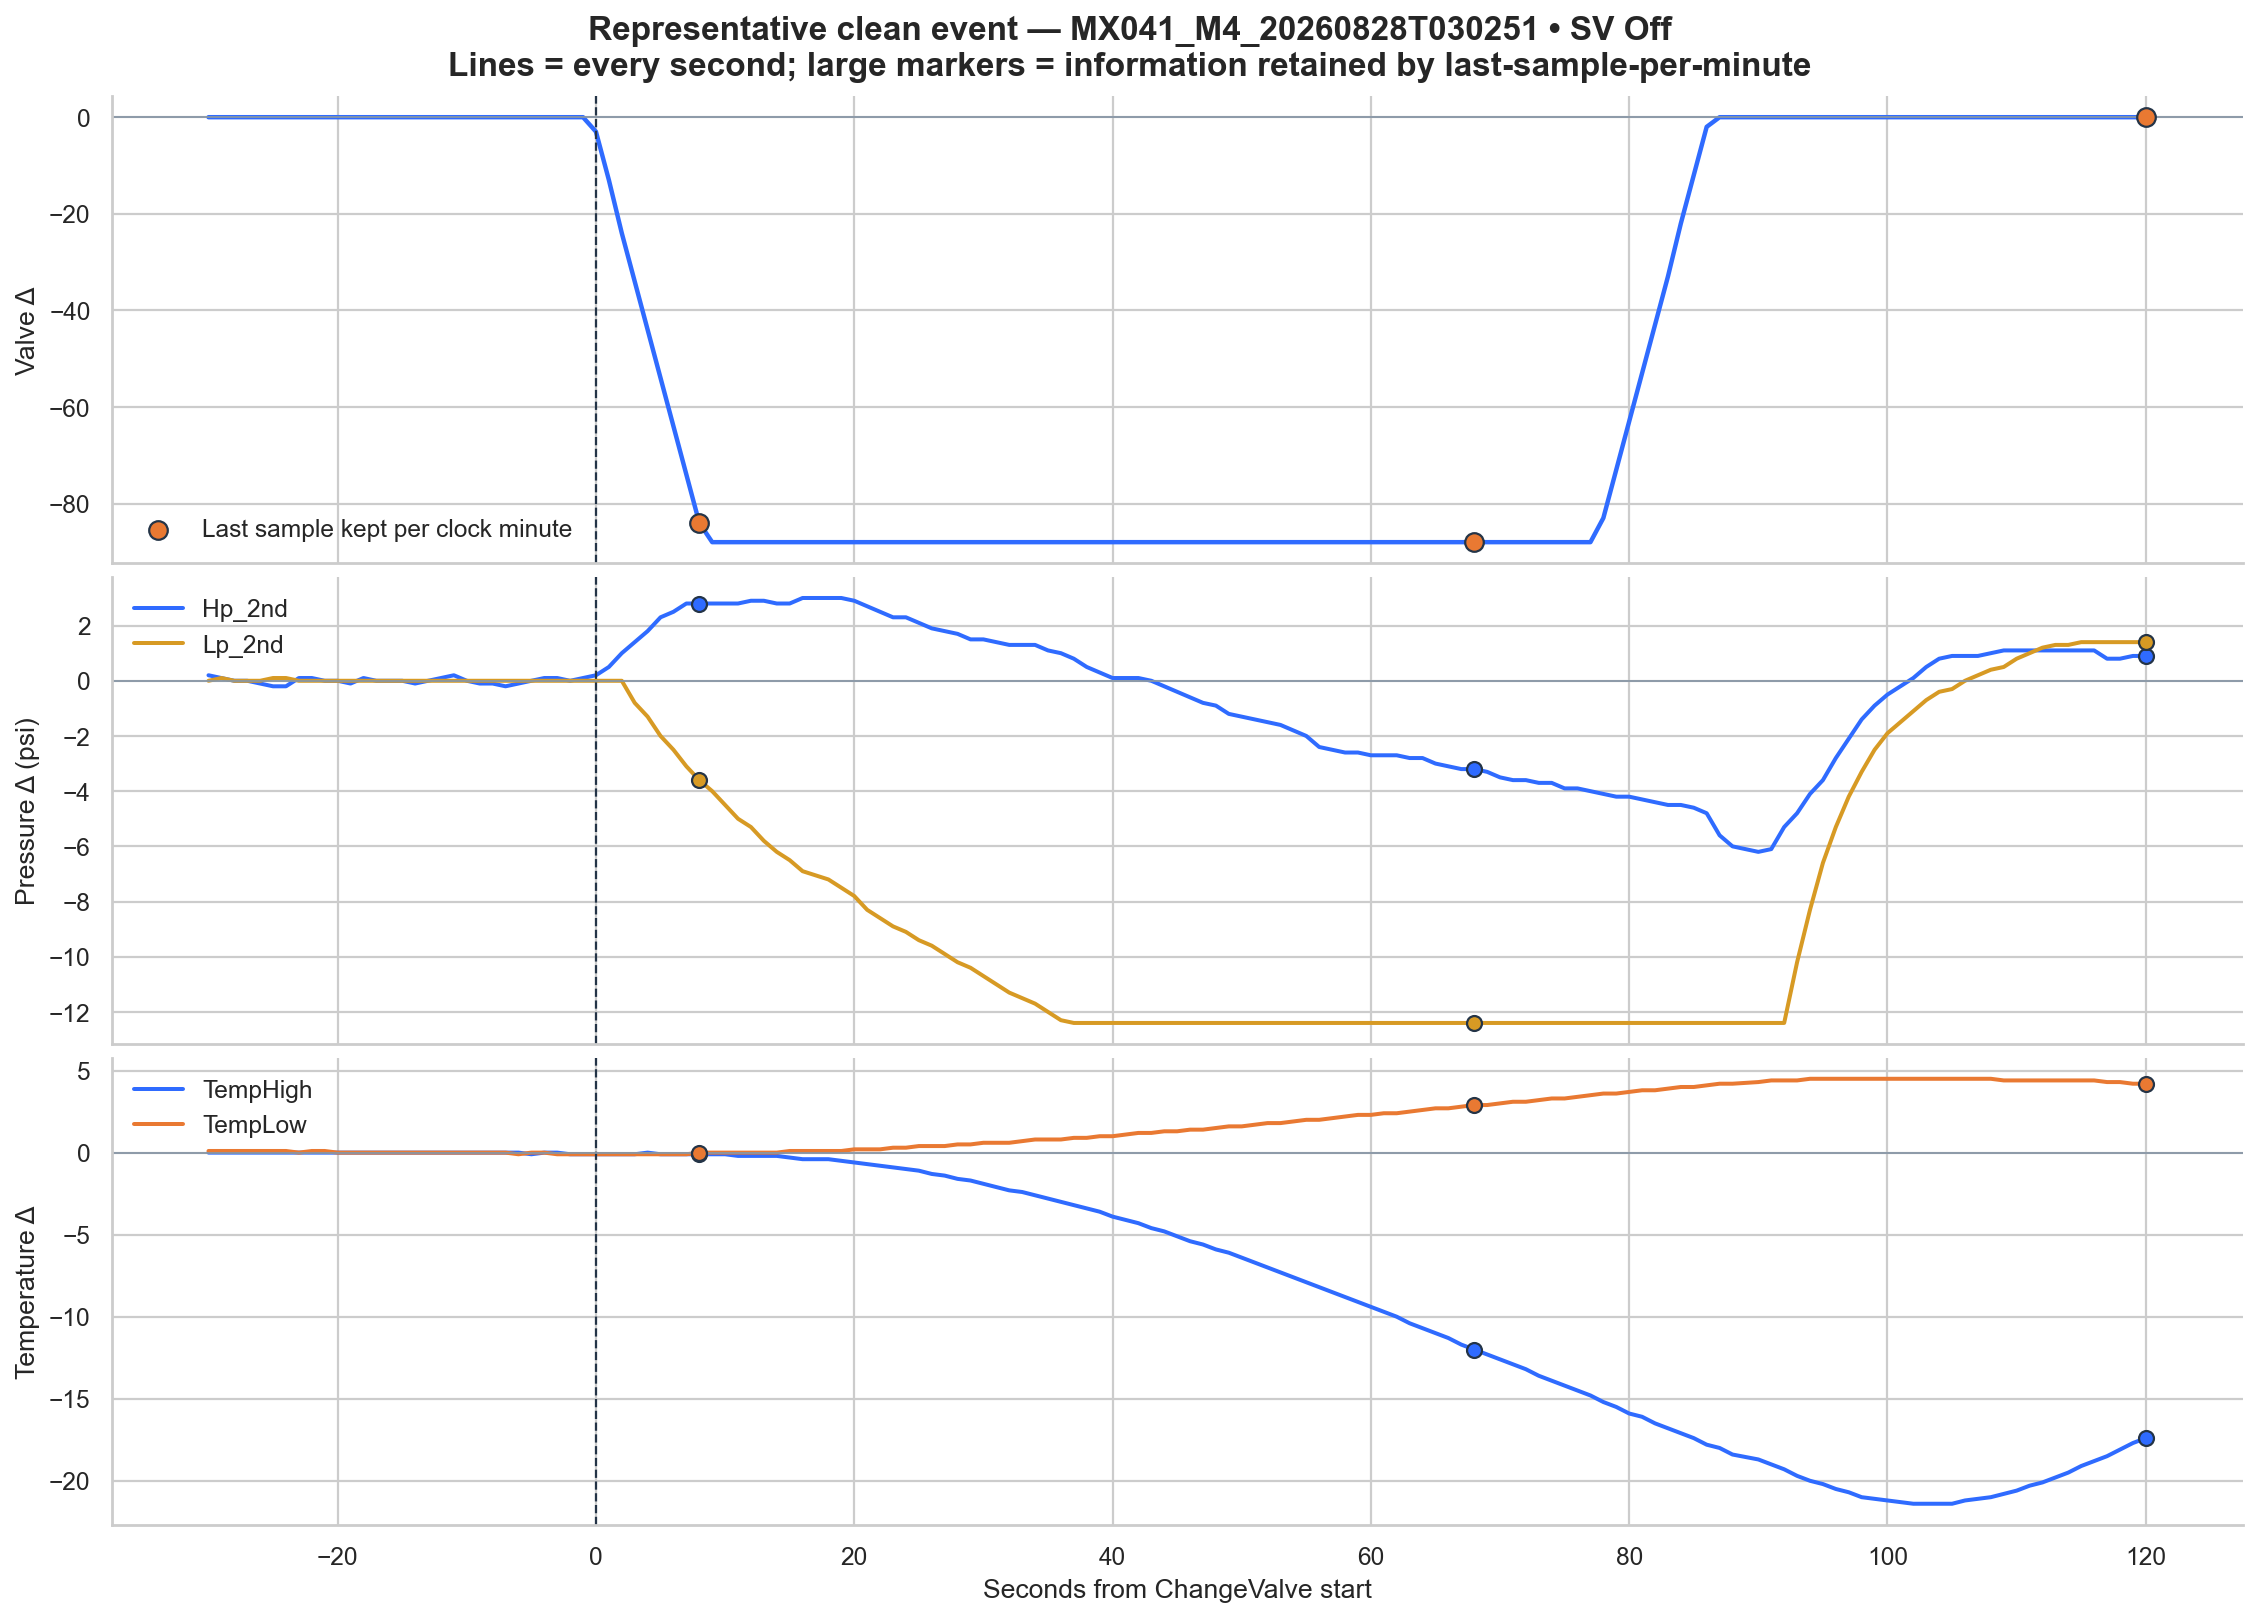

In [16]:
SECOND_OUT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_1s_window_analysis"
with open(SECOND_OUT / "analysis_summary.json", encoding="utf-8") as f:
    second_summary = json.load(f)

closing_60 = second_summary["closing_median_response"]["60s"]
closing_120 = second_summary["closing_median_response"]["120s"]
display(Markdown(f'''
### ผลที่อ่านได้จากข้อมูลจริง

- ระยะห่าง timestamp ใกล้ **1 วินาที {second_summary["one_second_interval_pct"]:.2f}%**
- พบจุดเริ่ม ChangeValve {second_summary["candidate_event_count"]:,} จุด และผ่าน qualification {second_summary["clean_event_count"]:,} events
- closing {second_summary["closing_event_count"]:,} events; opening {second_summary["opening_event_count"]:,} events — opening ยังน้อยเกินสรุป
- หลัง closing +60 วินาที: median ΔHp_2nd = {closing_60["hp2"]:+.1f} psi และ ΔLp_2nd = {closing_60["lp2"]:+.1f} psi
- หลัง closing +120 วินาที: median ΔTempHigh = {closing_120["temphi"]:+.1f} และ ΔTempLow = {closing_120["templo"]:+.1f}
'''))

from IPython.display import Image
import shutil

second_figures = {
    "02_event_aligned_response_curves.png": "09b_1second_event_response.png",
    "03_representative_event_1s_vs_1m.png": "09c_1second_vs_1minute.png",
}
for source_name, presentation_name in second_figures.items():
    source_path = SECOND_OUT / "figures" / source_name
    target_path = FIG_OUT / presentation_name
    shutil.copy2(source_path, target_path)
    display(Image(filename=str(target_path)))

### ทำอย่างไรให้ข้อมูล 1 นาทีเก็บความสัมพันธ์แบบ 1 วินาที

ห้ามเริ่มด้วยการเฉลี่ย raw signal เป็นรายนาที แล้วค่อยหา lag เพราะ onset, peak, valve return และ settling จะหายไป
ให้คำนวณ **micro-response features จากข้อมูล 1 วินาทีก่อน** แล้วค่อยผูกกลับเข้ากับแถวรายนาทีของ `event_start_minute`:

| Feature ต่อ event | ความหมาย |
|---|---|
| response at 5/15/30/60/120 s | การตอบสนองเร็วและช้าเทียบ pre-event baseline |
| peak absolute response + time-to-peak | ขนาดสูงสุดและเวลาที่เกิด |
| best lag / lagged correlation | delay ที่สัมพันธ์กับคำสั่ง valve มากที่สุด |
| valve net change + total variation | step จริงและอาการ hunting/แกว่ง |
| pre/post rolling slope | แนวโน้มก่อนและหลัง event |

สำหรับ online inference แบ่งเป็นสองชุด: **fast features** ที่พร้อมหลัง 5–30 วินาที และ **complete features** ที่พร้อมหลัง 60–120 วินาที
จากนั้นแบ่ง validation ตามเวลาที่ feature พร้อมจริง เพื่อไม่ให้ข้อมูลอนาคตรั่วกลับไปยังนาทีเริ่ม event.

## 6.3 Relative features — ทำให้เปรียบเทียบข้ามเครื่องได้

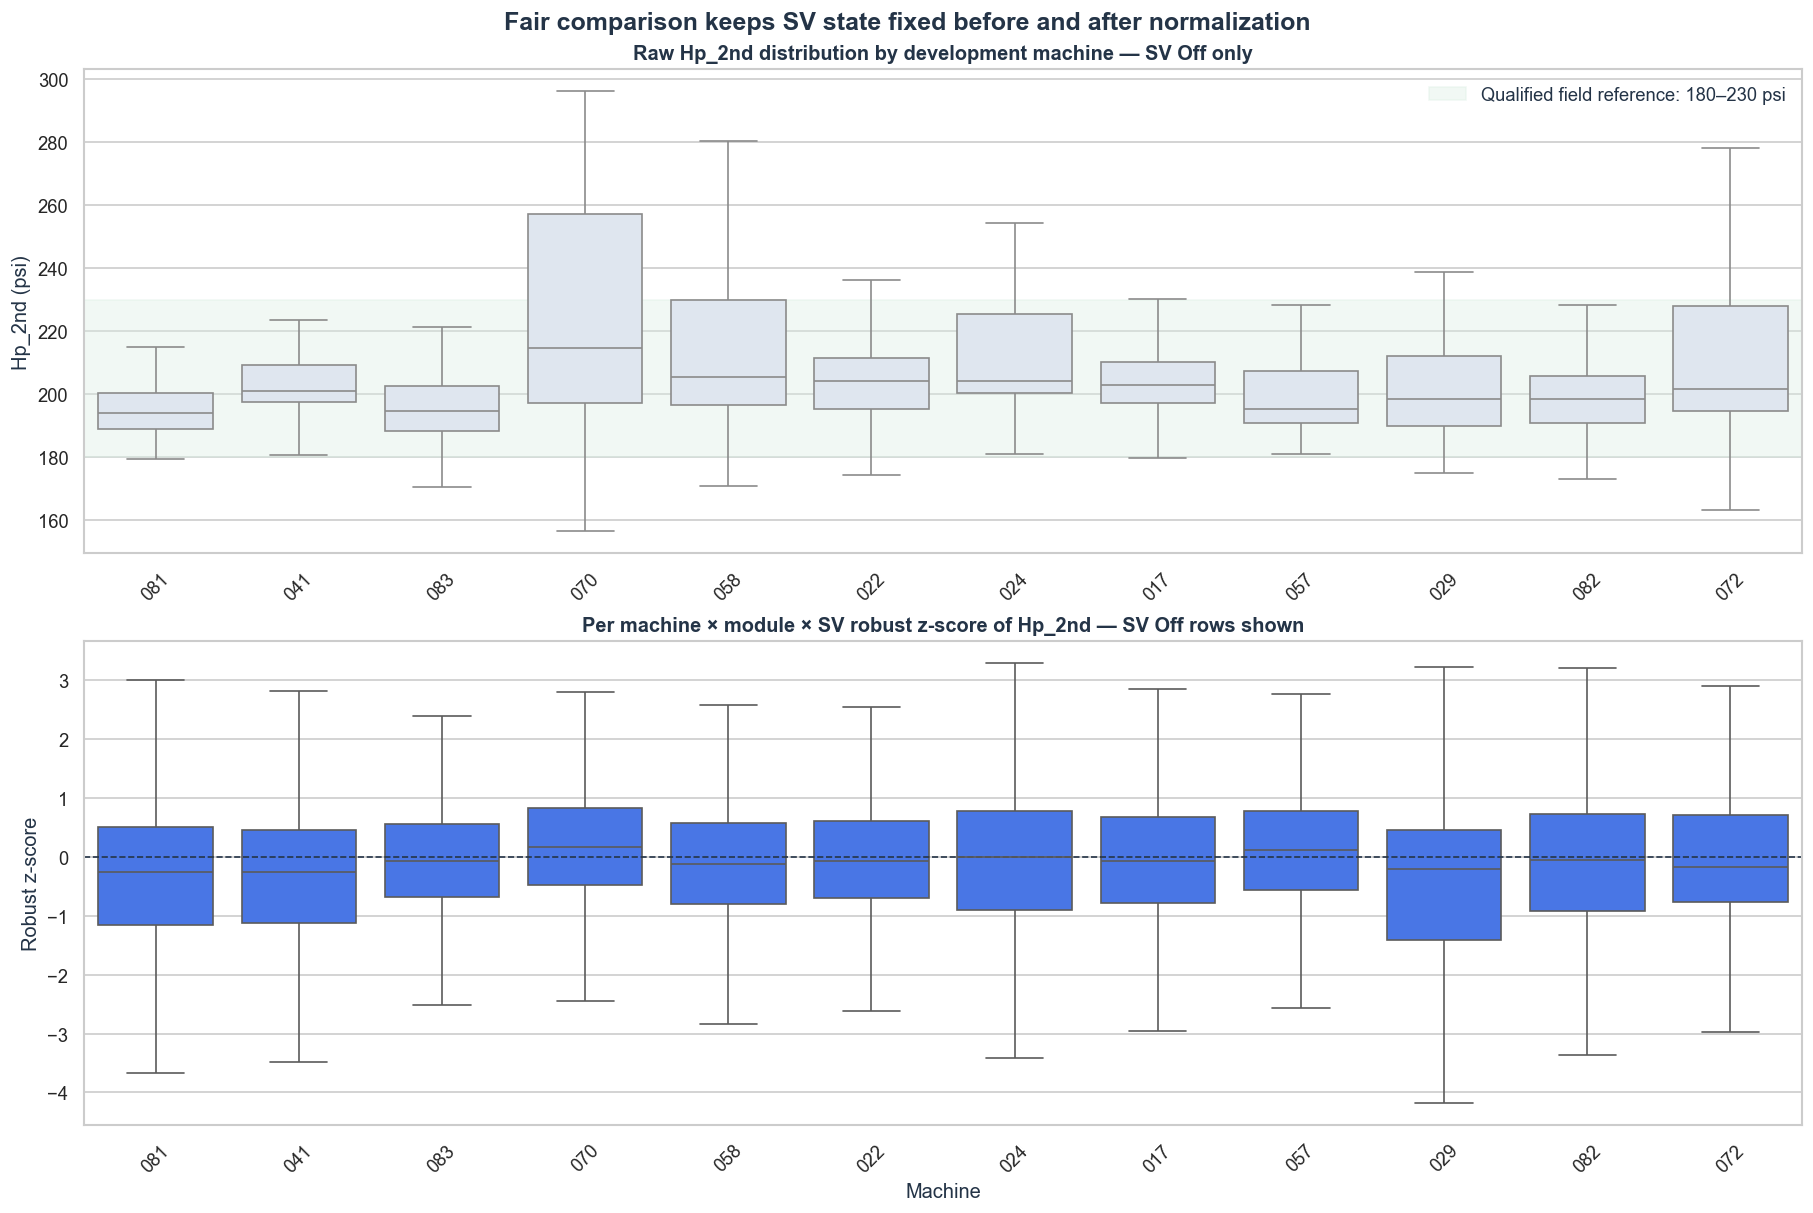

In [17]:
feature_file = ML_OUT / "ml_relative_features.parquet"
relative_rows = (
    pl.scan_parquet(feature_file)
    .filter(
        pl.col("machine_number").is_in(development_machines)
        & (pl.col("sv") == "Off")
    )
    .select(["machine_number", "rz_hp2"])
    .collect()
)
relative_sample = (
    relative_rows.sample(n=min(300000, relative_rows.height), seed=42)
    .to_pandas()
)
raw_rows = minute.filter(
    pl.col("baseline_eligible")
    & pl.col("machine_number").is_in(development_machines)
    & (pl.col("sv") == "Off")
).select(["machine_number", "hp2"])
raw_sample = raw_rows.sample(n=min(300000, raw_rows.height), seed=42).to_pandas()

fig, axes = plt.subplots(2, 1, figsize=(15, 10), constrained_layout=True)
sns.boxplot(data=raw_sample, x="machine_number", y="hp2", color=PALETTE["light"],
            showfliers=False, ax=axes[0])
axes[0].axhspan(180, 230, color="#DCEFE4", alpha=.4, label="Qualified field reference: 180–230 psi")
axes[0].set_title("Raw Hp_2nd distribution by development machine — SV Off only")
axes[0].set_xlabel("")
axes[0].set_ylabel("Hp_2nd (psi)")
axes[0].legend(frameon=False)
sns.boxplot(data=relative_sample, x="machine_number", y="rz_hp2", color=PALETTE["blue"],
            showfliers=False, ax=axes[1])
axes[1].axhline(0, color=PALETTE["ink"], lw=1, ls="--")
axes[1].set_title("Per machine × module × SV robust z-score of Hp_2nd — SV Off rows shown")
axes[1].set_xlabel("Machine")
axes[1].set_ylabel("Robust z-score")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Fair comparison keeps SV state fixed before and after normalization", fontsize=15, fontweight="bold")
savefig("10_relative_feature_normalization.png")
plt.show()

## 6.4 Feature policy — general anomaly vs undercharge evidence

โมเดล general anomaly ยังคงใช้ signed robust features เพื่อจับความเปลี่ยนแปลงได้ทั้งสองด้าน
แต่ undercharge screening ต้องใช้ feature ด้านต่ำเท่านั้น:

```python
hp2_low_deficit_psi = max(0, 180 - hp2)
hp2_low_rz          = max(0, -rz_hp2)
hp2_decline_rz      = max(0, -rz_hp2_slope_15m)
```

ถ้า `Hp_2nd >= 180 psi` ทั้ง `hp2_low_deficit_psi` และ leak contribution จาก `Hp_2nd` ต้องเป็นศูนย์
ส่วน `Lp_2nd`, valve demand, cooling performance และ persistence ใช้เป็นหลักฐานประกอบ ไม่ใช่ label อัตโนมัติ.

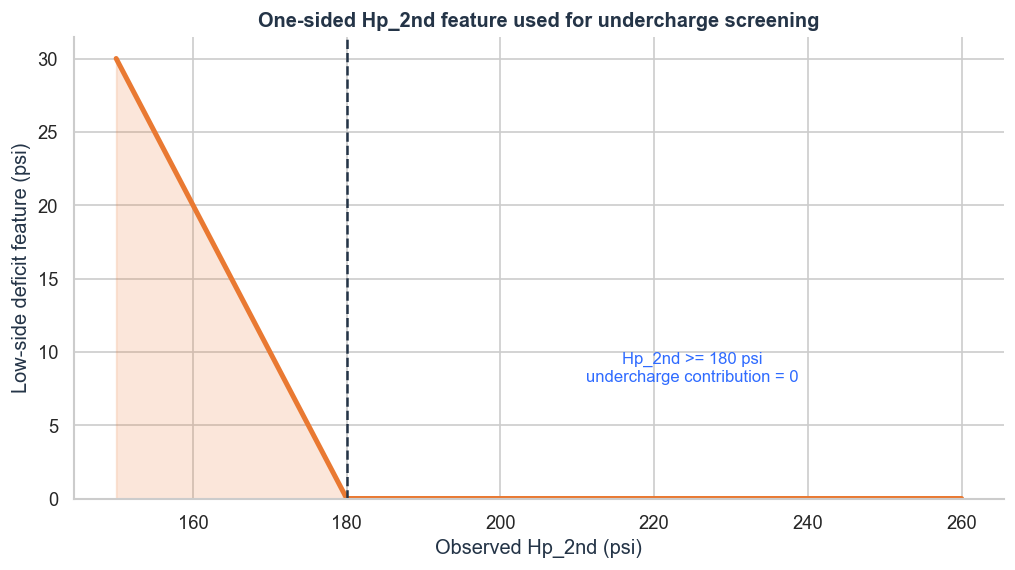

In [18]:
feature_demo_x = np.linspace(150, 260, 221)
feature_demo_y = np.maximum(0, HP2_LOW_GUARDRAIL_PSI - feature_demo_x)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(feature_demo_x, feature_demo_y, color=PALETTE["orange"], lw=3)
ax.axvline(HP2_LOW_GUARDRAIL_PSI, color=PALETTE["ink"], ls="--", lw=1.5)
ax.fill_between(feature_demo_x, 0, feature_demo_y, where=feature_demo_x < 180,
                color=PALETTE["orange"], alpha=.18)
ax.text(225, 8, "Hp_2nd >= 180 psi\nundercharge contribution = 0", ha="center", color=PALETTE["blue"])
ax.set_xlabel("Observed Hp_2nd (psi)")
ax.set_ylabel("Low-side deficit feature (psi)")
ax.set_title("One-sided Hp_2nd feature used for undercharge screening")
ax.set_ylim(bottom=0)
sns.despine()
savefig("10b_one_sided_hp2_feature.png")
plt.show()

กราฟทั้งสองส่วนแสดงเฉพาะ `SV=OFF` เพื่อไม่เปรียบเทียบคนละ operating state.
กราฟบนคือค่าจริงที่ baseline แตกต่างระหว่างเครื่อง ส่วนกราฟล่างเปลี่ยนเป็นระยะห่างจาก baseline ของ
machine × module × SV ของตัวเอง จึงเหมาะกับ shared model มากกว่าใช้ pressure absolute ร่วมกันทั้ง fleet.

# Phase 7 — Train the general anomaly ML model

Phase นี้เทรน `IsolationForest` จริงด้วยข้อมูลช่วงต้น 70% ของเครื่อง development เท่านั้น
เพื่อหลีกเลี่ยง look-ahead leakage แล้ววัดผลกับช่วงเวลาท้าย 30%.

ผลลัพธ์คือ **general anomaly score** ไม่ใช่ leak probability.
ค่าที่สูงกว่า 230 psi อาจถูก general model มองว่าต่างจากพฤติกรรมเดิม แต่ต้องไม่ถูกแปลเป็น undercharge หรือสาเหตุจากระบบน้ำโดยอัตโนมัติ.

## 7.1 General anomaly training

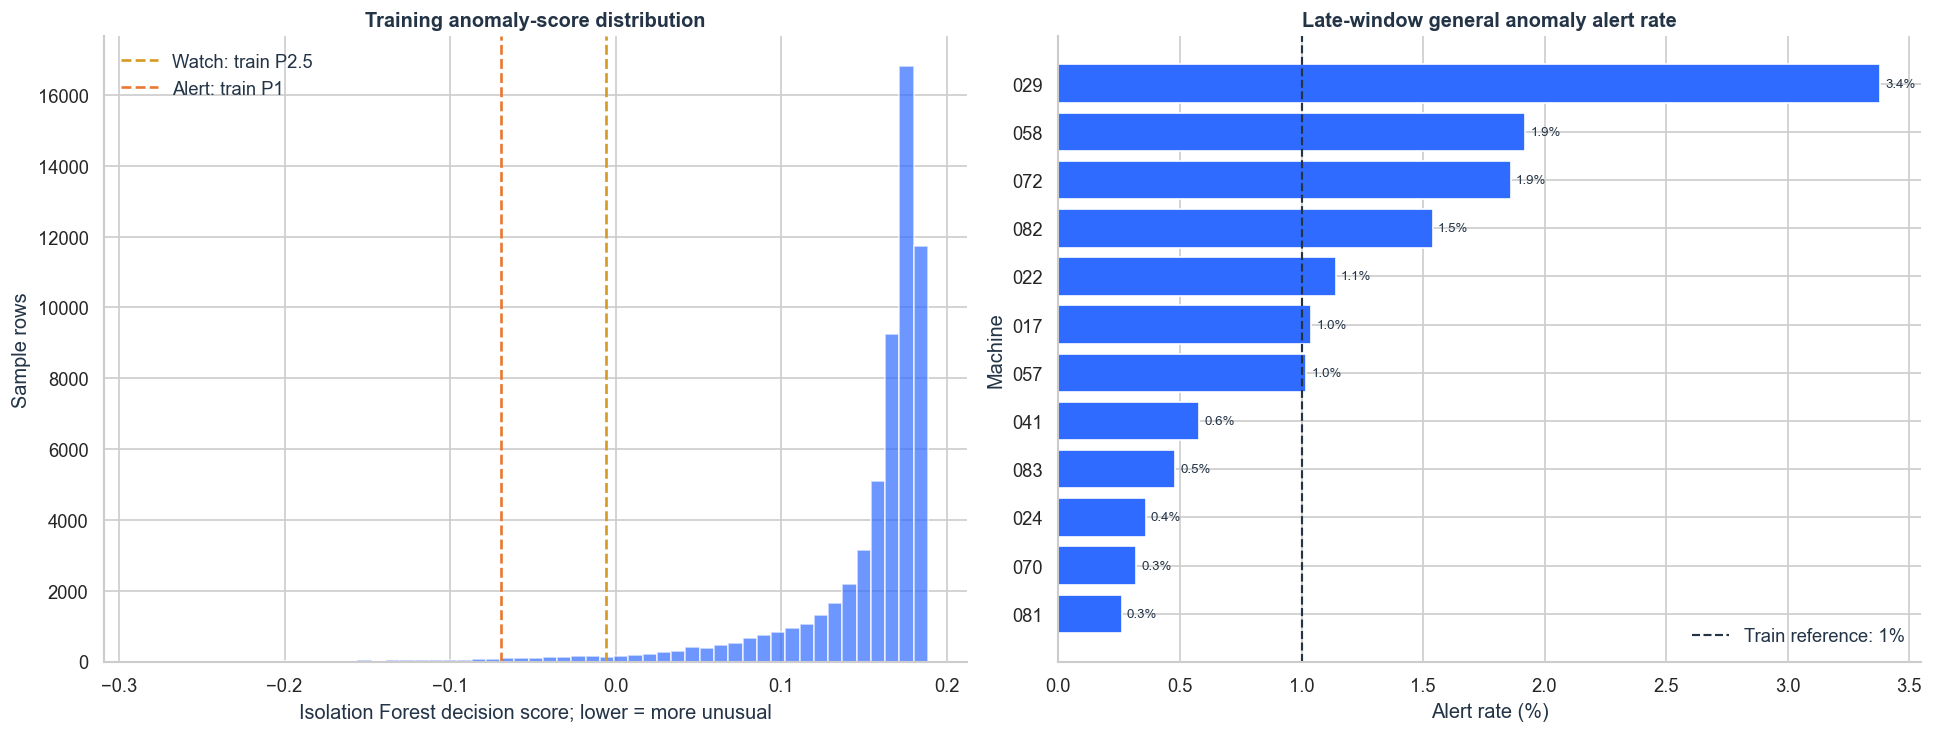

,Training summary,Value
0,Development machines,12
1,Training rows,60000
2,Late validation rows,60000
3,Features,32
4,Saved model,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...


In [19]:
feature_file = ML_OUT / "ml_relative_features.parquet"
feature_schema = pl.scan_parquet(feature_file).collect_schema()
model_features = [name for name in feature_schema.names() if name.startswith("rz_")]
id_columns = ["machine_number", "module", "sv", "minute", "is_profile_train"]

def balanced_feature_sample(is_train, per_machine=5000, seed=9046):
    pieces = []
    scan = pl.scan_parquet(feature_file)
    for offset, machine in enumerate(development_machines):
        part = (
            scan.filter(
                (pl.col("machine_number") == machine)
                & (pl.col("is_profile_train") == is_train)
            )
            .select([*id_columns, *model_features])
            .collect()
        )
        if part.height > per_machine:
            part = part.sample(n=per_machine, seed=seed + offset)
        pieces.append(part)
    return pl.concat(pieces, how="vertical").to_pandas()

train_sample = balanced_feature_sample(True, per_machine=5000)
late_sample = balanced_feature_sample(False, per_machine=5000, seed=10046)

imputer_v2 = SimpleImputer(strategy="median")
x_train = imputer_v2.fit_transform(train_sample[model_features])
general_model_v2 = IsolationForest(
    n_estimators=120,
    max_samples=min(2048, len(x_train)),
    contamination="auto",
    random_state=9046,
    n_jobs=-1,
)
general_model_v2.fit(x_train)
train_scores_v2 = general_model_v2.decision_function(x_train)
watch_threshold_v2 = float(np.quantile(train_scores_v2, .025))
alert_threshold_v2 = float(np.quantile(train_scores_v2, .010))

x_late = imputer_v2.transform(late_sample[model_features])
late_sample["anomaly_score"] = general_model_v2.decision_function(x_late)
late_sample["watch"] = late_sample["anomaly_score"] <= watch_threshold_v2
late_sample["alert"] = late_sample["anomaly_score"] <= alert_threshold_v2

trained_model_path = PRESENTATION_OUT / "general_relative_isolation_forest_v2.joblib"
joblib.dump({
    "model": general_model_v2,
    "imputer": imputer_v2,
    "model_features": model_features,
    "watch_threshold": watch_threshold_v2,
    "alert_threshold": alert_threshold_v2,
    "purpose": "general_anomaly_not_leak_classifier",
    "hp2_undercharge_guardrail_psi": HP2_LOW_GUARDRAIL_PSI,
}, trained_model_path)

late_rates_v2 = (
    late_sample.groupby("machine_number", as_index=False)
    .agg(n_scored=("alert", "size"), watch_rate_pct=("watch", lambda s: 100*s.mean()),
         alert_rate_pct=("alert", lambda s: 100*s.mean()))
    .sort_values("alert_rate_pct")
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
axes[0].hist(train_scores_v2, bins=55, color=PALETTE["blue"], alpha=.70, edgecolor="white")
axes[0].axvline(watch_threshold_v2, color=PALETTE["gold"], ls="--", lw=1.6, label="Watch: train P2.5")
axes[0].axvline(alert_threshold_v2, color=PALETTE["orange"], ls="--", lw=1.6, label="Alert: train P1")
axes[0].set_title("Training anomaly-score distribution")
axes[0].set_xlabel("Isolation Forest decision score; lower = more unusual")
axes[0].set_ylabel("Sample rows")
axes[0].legend(frameon=False)

bars = axes[1].barh(late_rates_v2["machine_number"], late_rates_v2["alert_rate_pct"],
                    color=PALETTE["blue"])
axes[1].axvline(1.0, color=PALETTE["ink"], ls="--", lw=1.3, label="Train reference: 1%")
axes[1].bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
axes[1].set_title("Late-window general anomaly alert rate")
axes[1].set_xlabel("Alert rate (%)")
axes[1].set_ylabel("Machine")
axes[1].legend(frameon=False)
sns.despine()
savefig("12_general_ml_training_and_late_validation.png")
plt.show()

display(pd.DataFrame({
    "Training summary": ["Development machines", "Training rows", "Late validation rows", "Features", "Saved model"],
    "Value": [len(development_machines), len(train_sample), len(late_sample), len(model_features), str(trained_model_path)],
}))

## 7.2 Minute-only vs second-derived models — เทรนและเปรียบเทียบแล้ว

การเปรียบเทียบใช้ qualified closing events ชุดเดียวกันและแบ่ง train/test ตามเวลา:

- **Minute-only:** relative baseline และ minute trend เดิม
- **Hybrid fast 30 s:** เพิ่ม response features ที่พร้อมภายใน 30 วินาที
- **Hybrid complete 120 s:** เพิ่ม peak, lag, hunting และ response 60/120 วินาที

Alert rate เป็นการวัด score stability ของ unsupervised model ไม่ใช่ accuracy ของ leak detection.

,model,n_events,watch_rate_pct,alert_rate_pct,median_score_change,new_alert_crossing_pct,features,train_rows_per_feature,available_after_s,p95_inference_ms,model_bundle_kib
0,Minute-only,73,8.219,2.740,0.000,0.000,19,8.421,0,40.258,1249.743
1,Hybrid fast 30 s,73,5.479,4.110,0.035,1.370,36,4.444,30,41.107,1239.842
2,Hybrid complete 120 s,73,8.219,5.479,0.046,5.479,58,2.759,120,40.683,1354.987


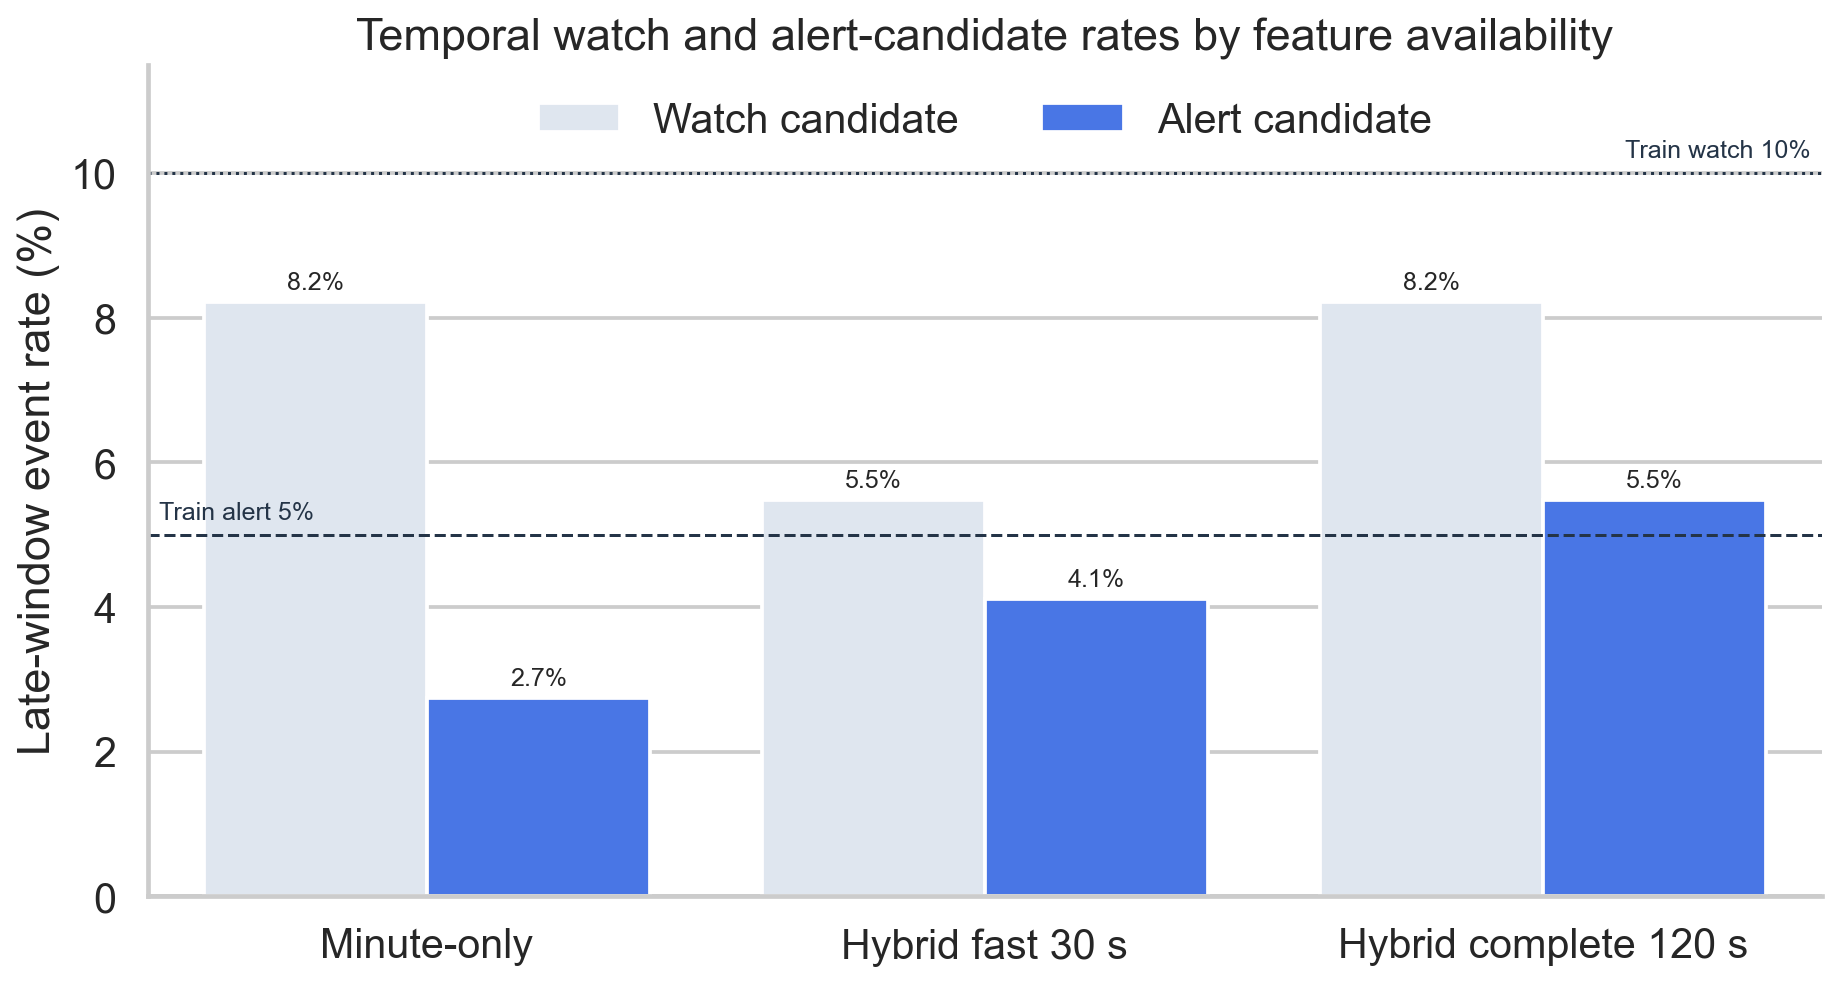

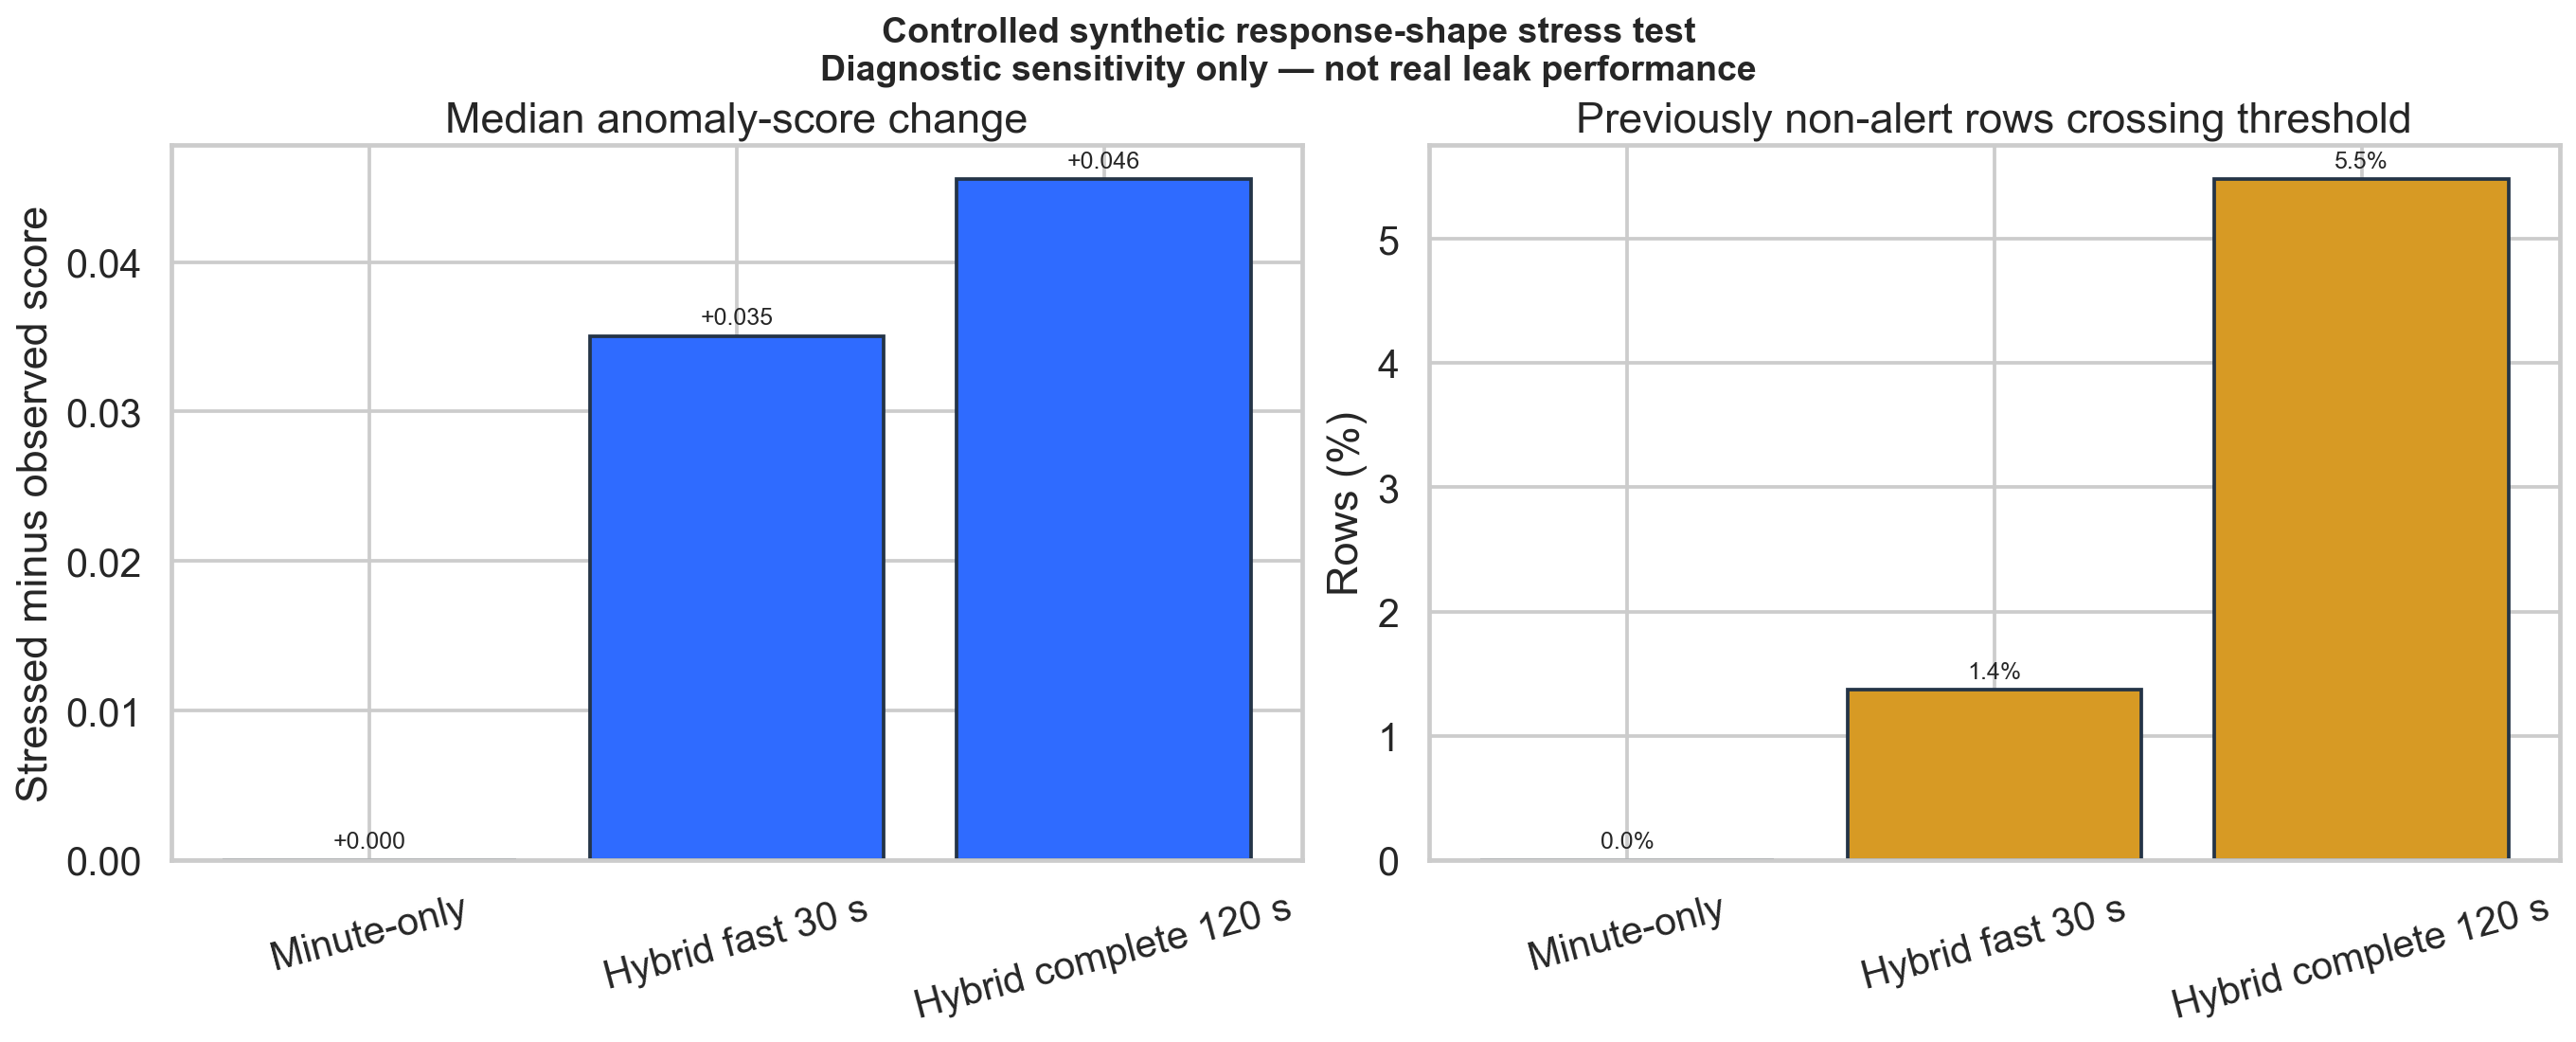

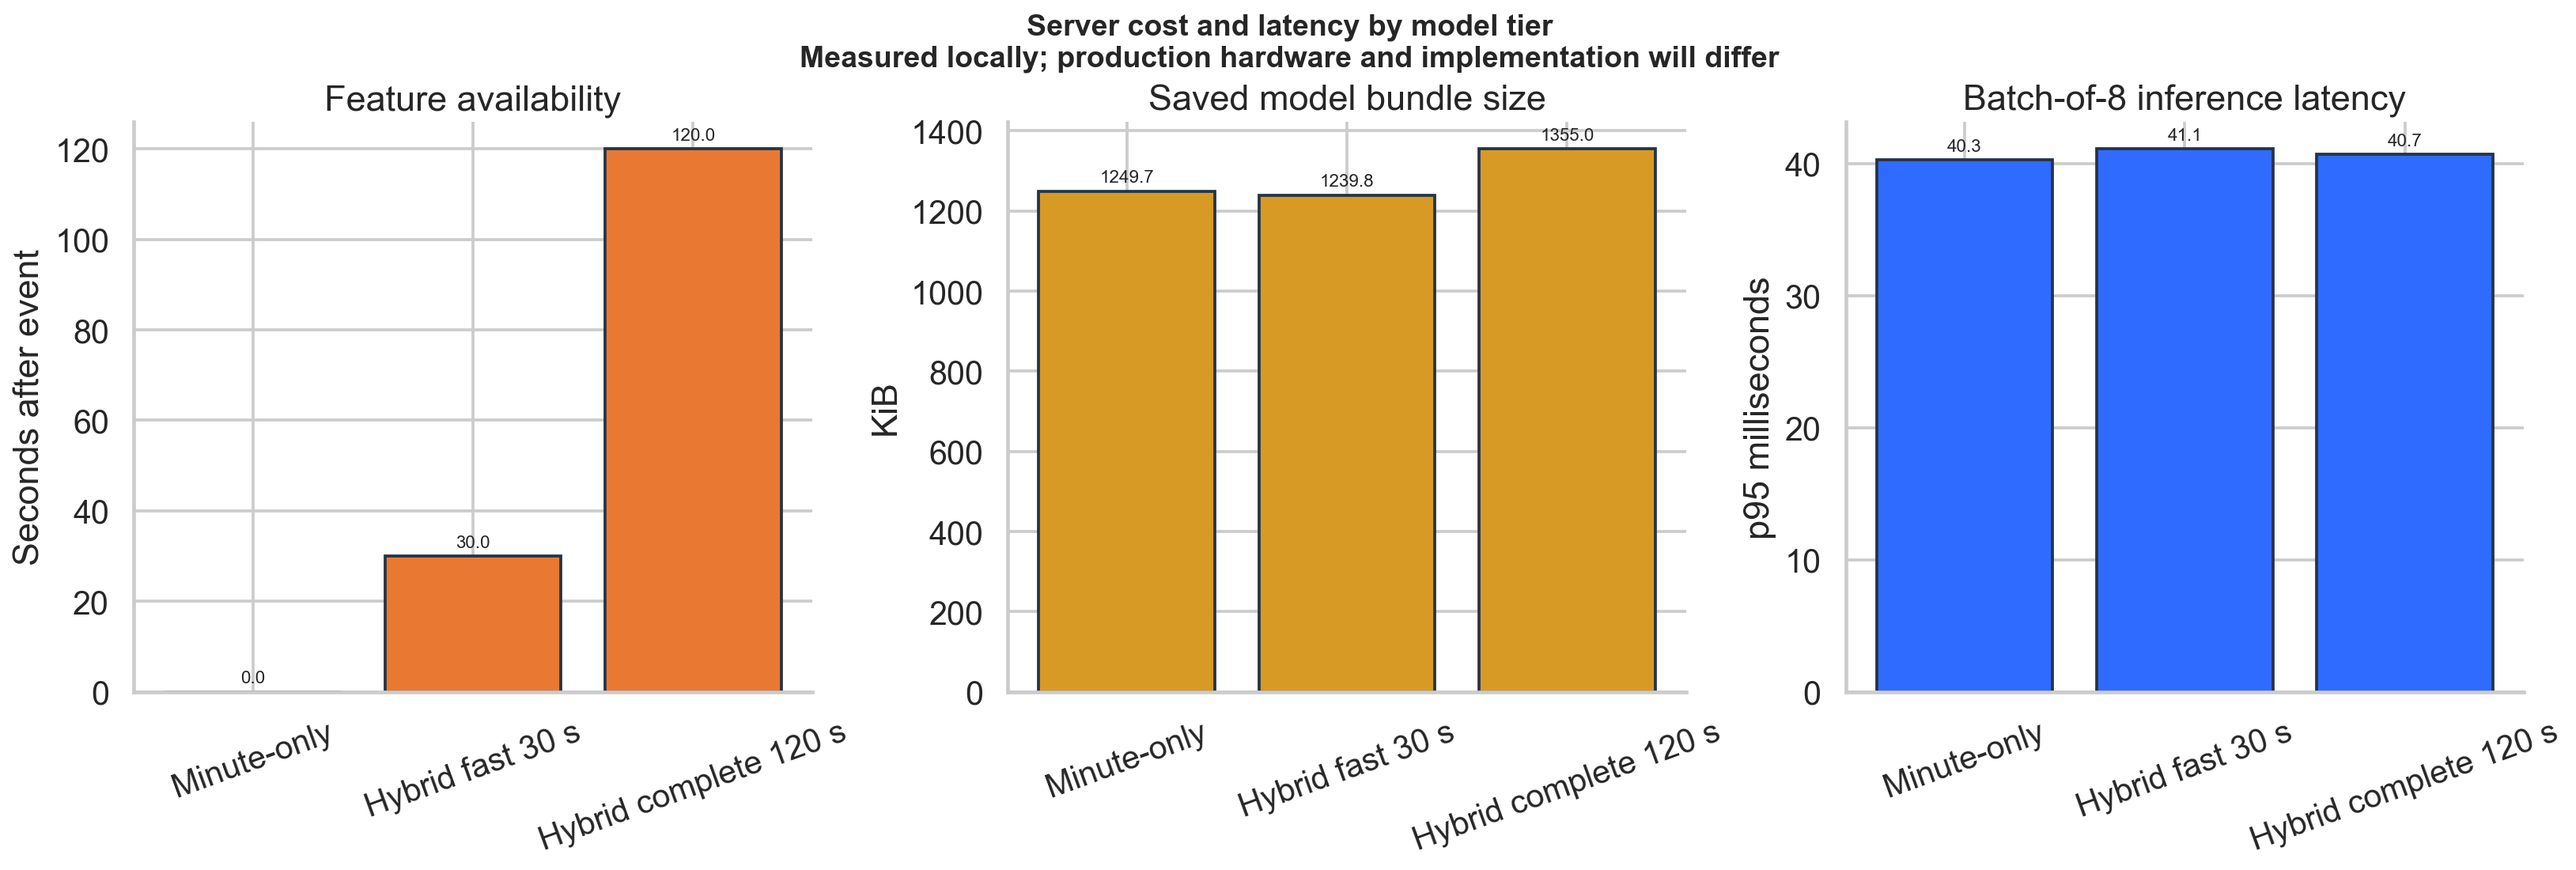

In [20]:
SECOND_ML_OUT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_ml_second_comparison"
with open(SECOND_ML_OUT / "analysis_summary.json", encoding="utf-8") as f:
    second_ml_summary = json.load(f)
second_model_comparison = pd.read_csv(SECOND_ML_OUT / "model_comparison_summary.csv")

display(second_model_comparison[[
    "model", "n_events", "watch_rate_pct", "alert_rate_pct",
    "median_score_change", "new_alert_crossing_pct", "features",
    "train_rows_per_feature", "available_after_s", "p95_inference_ms", "model_bundle_kib",
]].round(3))

from IPython.display import Image
import shutil

comparison_figures = {
    "01_temporal_model_comparison.png": "12b_minute_vs_second_temporal.png",
    "03_synthetic_response_sensitivity.png": "12c_response_sensitivity.png",
    "04_server_cost_tradeoff.png": "12d_server_cost_tradeoff.png",
}
for source_name, presentation_name in comparison_figures.items():
    source_path = SECOND_ML_OUT / "figures" / source_name
    target_path = FIG_OUT / presentation_name
    shutil.copy2(source_path, target_path)
    display(Image(filename=str(target_path)))

**คำตัดสิน:** second-derived features เพิ่ม sensitivity ต่อ response shape จริง แต่ complete model ยังมีเพียงประมาณ
2.8 training rows ต่อ feature และ MX081 LOMO มี n=3 จึงแกว่งถึง 100% alert candidate.

แนวทาง production ที่เหมาะสมคือ **Minute-only continuous monitor → Hybrid fast watch ที่ +30 s → Hybrid complete confirmation ที่ +120 s**
โดยรันแบบ event-driven ด้วย circular buffer 180 วินาที ไม่ต้อง score ทุกหนึ่งวินาที และต้องอยู่ใน shadow mode จนกว่าจะมี labels/coverage มากขึ้น.

## 7.3 Undercharge/leak layer — ยังไม่เทรน supervised classifier

ชุดข้อมูลปัจจุบันยังไม่มี technician-confirmed leak/healthy labels และ service timestamps ที่ครบถ้วน
ดังนั้น Notebook นี้ไม่สร้าง label ปลอมจาก `Hp_2nd < 180` หรือ `Hp_2nd > 230` แล้วนำไปเรียกว่า fault model.

การใช้งานที่ปลอดภัยในตอนนี้คือ:

1. ใช้ general ML หา pattern ที่ต่างจากเดิม
2. ใช้ one-sided `Hp_2nd` features คัดกรองเฉพาะด้านต่ำ
3. ต้องเห็นความต่อเนื่องและหลักฐานร่วมจาก `Lp_2nd`, valve และ performance
4. ส่งให้ช่างตรวจและบันทึกผลกลับมาเป็น label สำหรับ supervised model รุ่นถัดไป

# Phase 8 — Temporal, LOMO and external validation

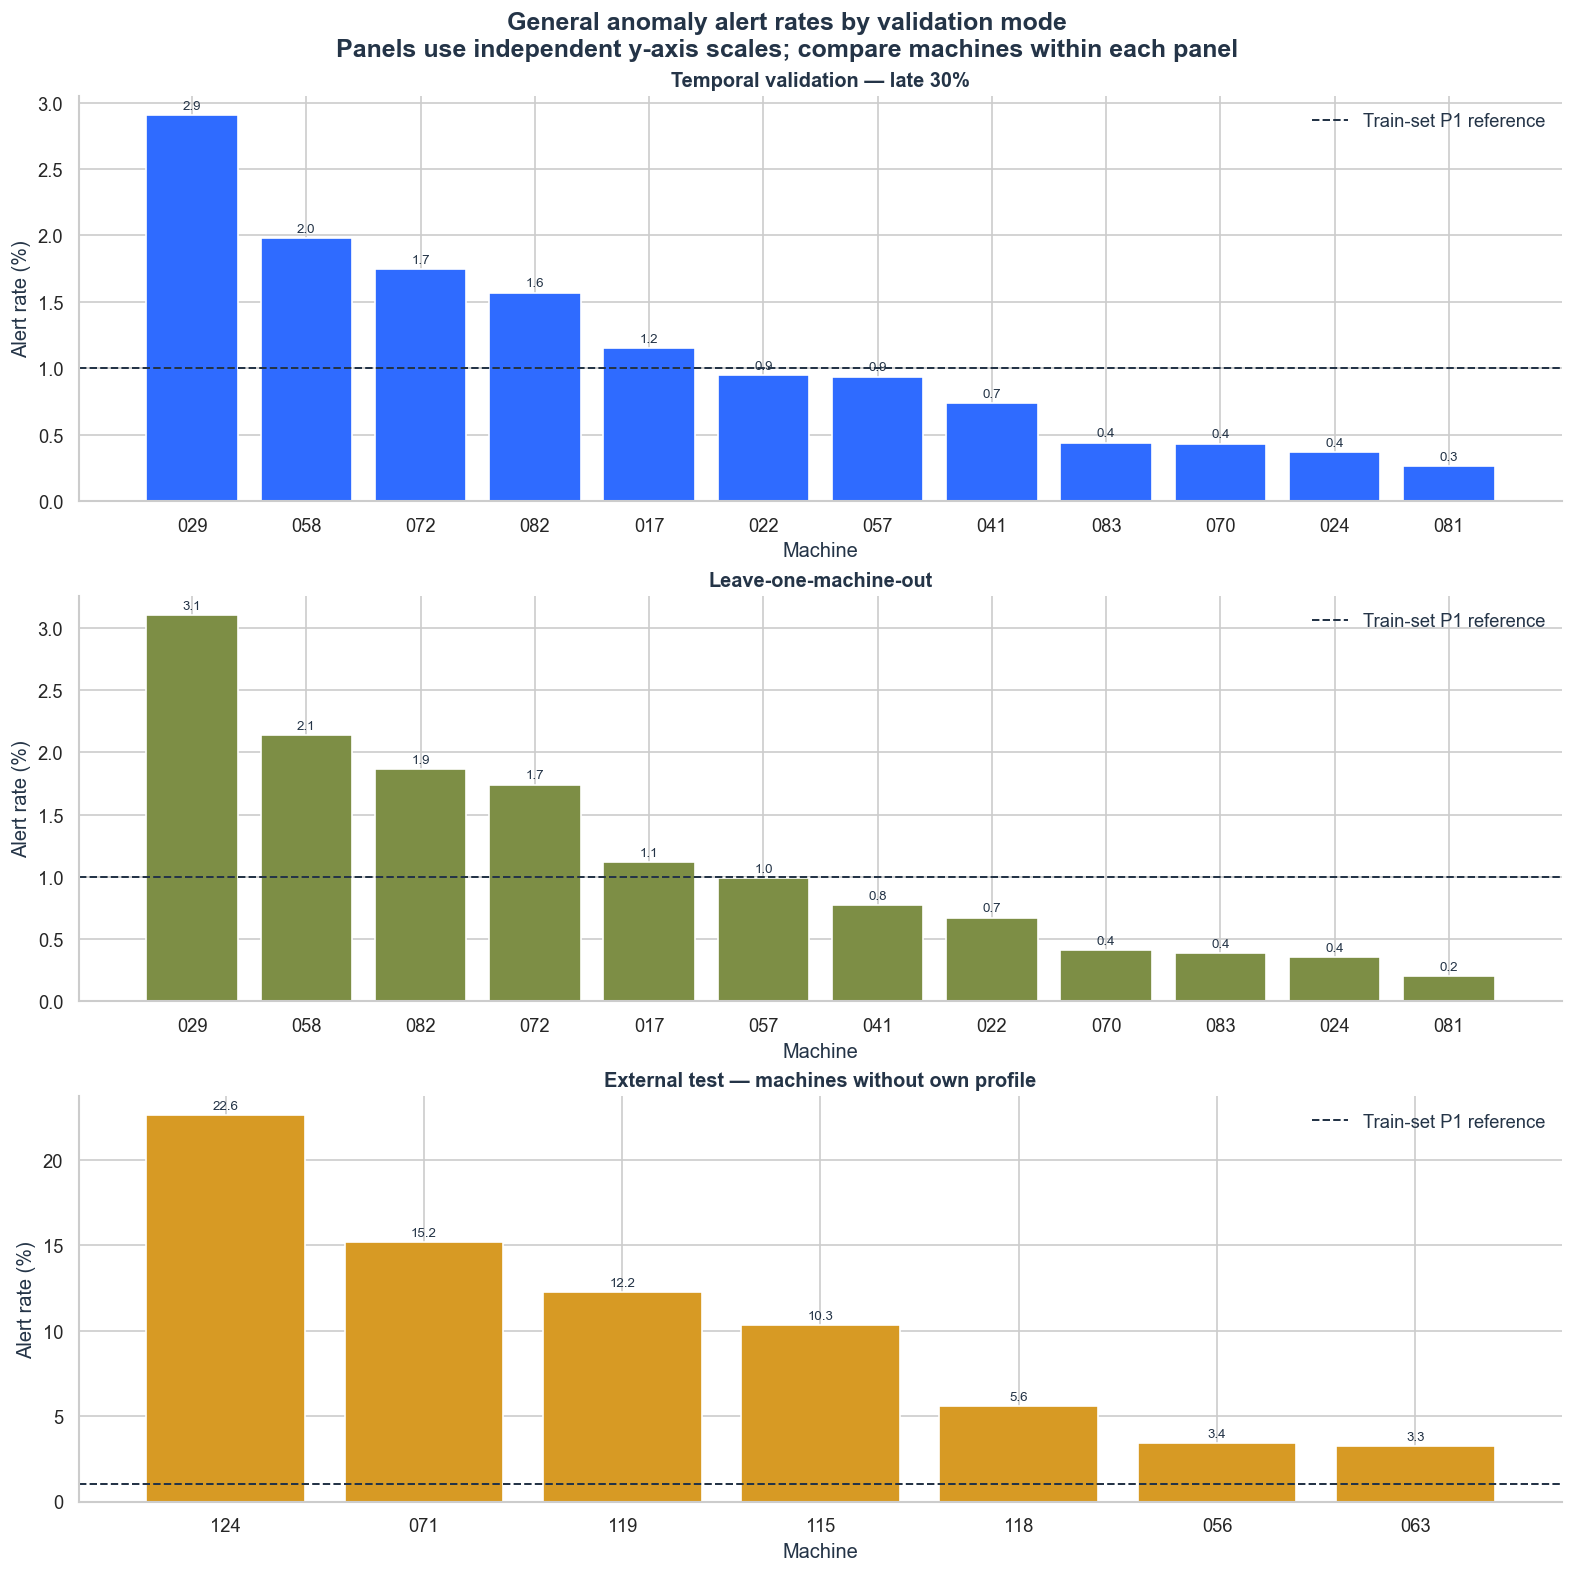

- Temporal median alert rate: **0.94%**  
- LOMO median alert rate: **0.88%**  
- External-test median alert rate: **10.34%**

In [21]:
temporal_plot = temporal.rename(columns={"machine_number": "machine"})[["machine", "alert_rate_pct"]].copy()
temporal_plot["validation"] = "Temporal (late 30%)"
lomo_plot = lomo.rename(columns={"held_out_machine": "machine"})[["machine", "alert_rate_pct"]].copy()
lomo_plot["validation"] = "LOMO"
external_plot = external.rename(columns={"machine_number": "machine"})[["machine", "alert_rate_pct"]].copy()
external_plot["validation"] = "External / cold start"

fig, axes = plt.subplots(3, 1, figsize=(13, 13), constrained_layout=True)
panels = [
    (temporal_plot, "Temporal validation — late 30%", PALETTE["blue"]),
    (lomo_plot, "Leave-one-machine-out", PALETTE["olive"]),
    (external_plot, "External test — machines without own profile", PALETTE["gold"]),
]
for ax, (p, title, color) in zip(axes, panels):
    p = p.sort_values("alert_rate_pct", ascending=False)
    bars = ax.bar(p["machine"], p["alert_rate_pct"], color=color)
    ax.axhline(1.0, color=PALETTE["ink"], ls="--", lw=1.2, label="Train-set P1 reference")
    ax.set_title(title)
    ax.set_ylabel("Alert rate (%)")
    ax.set_xlabel("Machine")
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
    ax.legend(frameon=False, loc="upper right")
    sns.despine(ax=ax)
fig.suptitle(
    "General anomaly alert rates by validation mode\n"
    "Panels use independent y-axis scales; compare machines within each panel",
    fontsize=15, fontweight="bold",
)
savefig("11_ml_validation.png")
plt.show()

display(Markdown(
    f"- Temporal median alert rate: **{ml_summary['temporal_validation_median_alert_pct']:.2f}%**  \n"
    f"- LOMO median alert rate: **{ml_summary['lomo_median_alert_pct']:.2f}%**  \n"
    f"- External-test median alert rate: **{ml_summary['external_test_median_alert_pct']:.2f}%**"
))

**วิธีอ่าน:** ค่า median ของ Temporal และ LOMO อยู่ใกล้ train-set reference แต่บางเครื่องสูงกว่าชัดเจน
จึงต้องอ่านแท่งรายเครื่อง ไม่ควรสรุปจาก median เพียงตัวเดียว ส่วน external test สูงกว่าเพราะใช้ fleet cold-start profile
แทน baseline ของเครื่องเอง ตัวเลข alert rate คือความต่างจาก reference ไม่ใช่ accuracy และยังไม่ใช่หลักฐานว่าเครื่องเสียหรือ leak.

# Phase 9 — Conclusions and deployment plan

In [22]:
takeaways = f'''
### สรุปสำหรับพรีเซ็นท์

1. **Baseline ไม่เท่ากันจริง** จึงต้อง calibrate แยก `machine × module × SV`.
2. ใช้ช่วงอ้างอิง **180–230 psi**: ต่ำกว่า 180 เป็น undercharge screening; สูงกว่า 230 เป็น high-side investigation และไม่เพิ่ม leak score.
3. ค่า `Hp_2nd` ต่ำครั้งเดียวไม่ใช่ leak ต้องดู persistence, negative trend, `Lp_2nd`, valve, performance และผลตรวจช่างร่วมกัน.
4. Positive daily jump เป็นเพียง service/refill candidate จนกว่าจะผูกกับ maintenance log; เมื่อยืนยันแล้วต้องเริ่ม calibration epoch ใหม่.
5. โมเดลที่เทรนทั้งหมดเป็น **general anomaly model** ไม่ใช่ leak classifier.
6. Event window ระดับ 1 วินาทีเห็น pressure response ในช่วง 15–60 วินาที และ temperature response ที่ช้ากว่า.
7. ผล temporal บน 73 events: Minute-only alert 2.74%, Hybrid fast 4.11% และ Hybrid complete 5.48%; hybrid มองเห็น synthetic response-shape change ที่ minute-only มองไม่เห็น.
8. ภาระ Server ต่ำ: model ประมาณ 1.2–1.4 MiB, batch 8 p95 ต่ำกว่า 50 ms และ ring-buffer payload 19 เครื่องประมาณ 2.5 MiB; ความเสี่ยงหลักคือ coverage/state correctness ไม่ใช่ compute.
9. Complete model ยังไวเกินไปในกลุ่มตัวอย่างน้อย จึงใช้เป็น confirmation ใน shadow mode ไม่ใช่แทนโมเดลเดิมทันที.

### แผนนำไปใช้งาน

| ลำดับ | งาน | เกณฑ์ผ่าน |
|---:|---|---|
| 1 | เพิ่ม service/refill timestamp และผล leak test | ระบุ baseline epoch ได้ |
| 2 | เพิ่ม recipe, phase, target/actual temperature และ facility water | เปรียบเทียบ operating context ได้ |
| 3 | รัน Minute-only → Hybrid fast → Hybrid complete แบบสองชั้นใน shadow mode | ตรวจ false alarms ราย machine/module/event |
| 4 | ให้ช่างยืนยัน alert และบันทึกสาเหตุ | ได้ trustworthy labels |
| 5 | เทรน supervised undercharge classifier | รายงาน precision, recall, lead time และ false alarms/day |
| 6 | ทดสอบ temporal + LOMO + เครื่องข้อมูลน้อย | ผ่านก่อนเปิดแจ้งเตือนจริง |

### สถานะความพร้อม

**Share with caveats:** พร้อมใช้พรีเซ็นท์เพื่ออธิบายวิธีวิเคราะห์และทดลอง shadow mode
แต่ยังไม่พร้อมใช้ยืนยัน leak หรือสั่งซ่อมอัตโนมัติ เพราะยังไม่มี maintenance labels และ service-event ground truth ที่ครบถ้วน
'''
display(Markdown(takeaways))


### สรุปสำหรับพรีเซ็นท์

1. **Baseline ไม่เท่ากันจริง** จึงต้อง calibrate แยก `machine × module × SV`.
2. ใช้ช่วงอ้างอิง **180–230 psi**: ต่ำกว่า 180 เป็น undercharge screening; สูงกว่า 230 เป็น high-side investigation และไม่เพิ่ม leak score.
3. ค่า `Hp_2nd` ต่ำครั้งเดียวไม่ใช่ leak ต้องดู persistence, negative trend, `Lp_2nd`, valve, performance และผลตรวจช่างร่วมกัน.
4. Positive daily jump เป็นเพียง service/refill candidate จนกว่าจะผูกกับ maintenance log; เมื่อยืนยันแล้วต้องเริ่ม calibration epoch ใหม่.
5. โมเดลที่เทรนทั้งหมดเป็น **general anomaly model** ไม่ใช่ leak classifier.
6. Event window ระดับ 1 วินาทีเห็น pressure response ในช่วง 15–60 วินาที และ temperature response ที่ช้ากว่า.
7. ผล temporal บน 73 events: Minute-only alert 2.74%, Hybrid fast 4.11% และ Hybrid complete 5.48%; hybrid มองเห็น synthetic response-shape change ที่ minute-only มองไม่เห็น.
8. ภาระ Server ต่ำ: model ประมาณ 1.2–1.4 MiB, batch 8 p95 ต่ำกว่า 50 ms และ ring-buffer payload 19 เครื่องประมาณ 2.5 MiB; ความเสี่ยงหลักคือ coverage/state correctness ไม่ใช่ compute.
9. Complete model ยังไวเกินไปในกลุ่มตัวอย่างน้อย จึงใช้เป็น confirmation ใน shadow mode ไม่ใช่แทนโมเดลเดิมทันที.

### แผนนำไปใช้งาน

| ลำดับ | งาน | เกณฑ์ผ่าน |
|---:|---|---|
| 1 | เพิ่ม service/refill timestamp และผล leak test | ระบุ baseline epoch ได้ |
| 2 | เพิ่ม recipe, phase, target/actual temperature และ facility water | เปรียบเทียบ operating context ได้ |
| 3 | รัน Minute-only → Hybrid fast → Hybrid complete แบบสองชั้นใน shadow mode | ตรวจ false alarms ราย machine/module/event |
| 4 | ให้ช่างยืนยัน alert และบันทึกสาเหตุ | ได้ trustworthy labels |
| 5 | เทรน supervised undercharge classifier | รายงาน precision, recall, lead time และ false alarms/day |
| 6 | ทดสอบ temporal + LOMO + เครื่องข้อมูลน้อย | ผ่านก่อนเปิดแจ้งเตือนจริง |

### สถานะความพร้อม

**Share with caveats:** พร้อมใช้พรีเซ็นท์เพื่ออธิบายวิธีวิเคราะห์และทดลอง shadow mode
แต่ยังไม่พร้อมใช้ยืนยัน leak หรือสั่งซ่อมอัตโนมัติ เพราะยังไม่มี maintenance labels และ service-event ground truth ที่ครบถ้วน


# Appendix — Exported figures

กราฟหลักทั้งหมดถูกบันทึกไว้ใน `notebooks/outputs/ht9046mx_presentation_v2/figures/` เมื่อรัน notebook จบ
สามารถนำ PNG ไปใช้ในรายงานหรือ presentation ต่อได้ โดยชื่อไฟล์เรียงตามลำดับเรื่องที่เล่า.

In [23]:
exported = sorted(FIG_OUT.glob("*.png"))
pd.DataFrame({"figure": [p.name for p in exported], "path": [str(p) for p in exported]})

,figure,path
0,01_machine_coverage.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
1,02_state_composition.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
2,03_baseline_comparability.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
3,04_baseline_map_hp2_off.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
4,05_machine_017_hp2_baseline_interval.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
5,05b_hp2_machine_interval_sv_off.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
6,05c_hp2_low_deficit_heatmap_sv_off.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
7,06_machine_017_correlations_off.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
8,06a_normal_vs_relationship_017_m1_off.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
9,07_detail_017_m1_off.png,C:\Users\Book\OneDrive\Documents\ChatGPT\OPERA...
